In [ ]:
> Historical saved outputs are preserved below. Embedded WAV playback outputs were omitted from this public copy; the complete recovered notebook remains in the local BTP directory.

from pathlib import Path
import io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

import os
ROOT = Path(os.environ.get("BTP_ROOT", Path.cwd())).resolve()
A_DIR = ROOT / "raw" / "A_narration" / "data"
files = sorted(A_DIR.glob("*/*.parquet"))
print(len(files), "parquet files found")   # expect 59

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)



In [7]:
rows = []
for f in files:
    pf = pq.ParquetFile(f)
    rows.append({"split": f.parent.name, "file": f.name,
                 "rows": pf.metadata.num_rows, "row_groups": pf.metadata.num_row_groups})
file_table = pd.DataFrame(rows)
display(file_table.groupby("split").agg(files=("file", "count"), rows=("rows", "sum")))
display(file_table.head(30))

,files,rows
split,,
test,6,684
train,46,5305
validation,7,729


,split,file,rows,row_groups
0,test,data-083f238c.parquet,50,1
1,test,data-2cf54942.parquet,426,5
2,test,data-756603b7.parquet,50,1
3,test,data-7ef0d7c8.parquet,51,1
4,test,data-aefffea7.parquet,47,1
5,test,data-babc44cf.parquet,60,1
6,train,data-0d68d838.parquet,117,2
7,train,data-17ae335f.parquet,78,1
8,train,data-1867a0cb.parquet,50,1
9,train,data-1aef74ba.parquet,50,1


In [8]:
text_cols = [c for c in pq.ParquetFile(files[0]).schema_arrow.names if c != "audio"]

parts = []
for f in files:
    part = pq.read_table(f, columns=text_cols).to_pandas()
    part.insert(0, "split", f.parent.name)       # which split folder it came from
    part.insert(1, "file", f.name)               # which parquet file
    part.insert(2, "row_in_file", range(len(part)))  # row number inside that file (used to find the audio)
    parts.append(part)

df = pd.concat(parts, ignore_index=True)
print(df.shape)   # expect (6718, 28)

(6718, 28)


In [9]:
df.head(10)

,split,file,row_in_file,audio_id,Domain,Elicitation Method,Q_Id,boundaryID,end_time,filename,publicSpeakerId,sentence-IPA-transcription,sentenceId,speaker1-ageGroup,speaker1-educationLevel,speaker1-educationMediumAfter12-list,speaker1-educationMediumUpto12-list,speaker1-gender,speaker1-lifespeakerid,speaker1-otherLanguages-list,speaker1-placeOfRecording,speaker1-typeOfPlace,speaker2-ageGroup,speaker2-gender,speaker2-placeOfRecording,speaker2-typeOfPlace,speakerId,start_time
0,test,data-083f238c.parquet,0,A202506100851377938950011700557,Agriculture,Narration,AG_206,0011700557,5.57,T-6909.MT-3438357.MTA-4866ccc4ec5e41f4bffb830cb69abda3.A-562950053594623.W-22526.K-OutputRecording.R-9b33f02a968ba25...,6867765bff16e00b68f4bba2,mitun ham ŋun ɲokɯm pestibal holo sekripraiɟ malai deden,A20250610085137793895_0011700557,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,jorampaul1830_22526,1.17
1,test,data-083f238c.parquet,1,A202506100917530835240169702776,Culture,Narration,CLT_20,0169702776,27.76,T-6925.MT-3442912.MTA-a4f04d4d21e647fc9923888ac95ecc29.A-562950053594643.W-22526.K-OutputRecording.R-9b0e590880dffc2...,6867765bff16e00b68f4bba2,ta bialak bendən ɲisi gon boʃi nimʃi alba koisənam beŋka təna səm səmɟidup ta beana bendup pəca,A20250610091753083524_0169702776,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,jorampaul1830_22526,16.97
2,test,data-083f238c.parquet,2,A202506100939571642100099801600,Education,Narration,ED-08,0099801600,16.00,T-6926.MT-3442931.MTA-0547c91984b64d4e9d5947a0dac2597e.A-562950053594656.W-22526.K-OutputRecording.R-84ac724f61b22cb...,6867765bff16e00b68f4bba2,promi pori mabol ene biri sigret pilajel gomiŋam ugub ŋun ge dimag matael iː,A20250610093957164210_0099801600,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,jorampaul1830_22526,9.98
3,test,data-083f238c.parquet,3,A20250805170539197219,Science-Technology,Narration,ST_96,0006802449,24.49,T-6930.MT-3443233.MTA-8b0f069bf83e4c7c8faa521e4a373d04.A-562950053594706.W-22526.K-OutputRecording.R-a640ad53fc03a10...,6867765bff16e00b68f4bba2,gariŋam cabi aləktəl eksiletaram gabuktəl klacam gabuktəl giaram aləktəl ene e parbin suma bo ene en giaram utaitel ...,A20250805170539197219_0006802449,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,jorampaul1830_22526,0.68
4,test,data-083f238c.parquet,4,A202506100930173563760112002477,Education,Narration,ED-20,0112002477,24.77,T-6926.MT-3442943.MTA-f0b7464901e744b09dd761ec141eb663.A-562950053661061.W-23032.K-OutputRecording.R-b79b109537217da...,6867765bff16e00b68f4bba4,uɡlu mahesiɟa liɟakəm nətɪs lencot̪ai holit̪ai hebnel ɟaha t̪aha liɡu likma ho ɛdjʊkeɪʃn dolail kulsiɟan nətɪshe nai...,A20250610093017356376_0112002477,18-30,N/A,N/A,N/A,Female,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,likhaaku1830_23032,11.20
5,test,data-083f238c.parquet,5,A202506100927073213200061902519,Education,Narration,ED-28,0061902519,25.19,T-6926.MT-3442951.MTA-90ef86c285b44ff5b25611e6d43d2042.A-562950053594657.W-22536.K-OutputRecording.R-ab02b823d7c86ee...,6867765bff16e00b68f4bba6,o aɟina rumnəŋam kam aija poriənbəŋ dodo hoge alma porboŋkam dodo hoge noke alma nil dota ma lekin eɟukeʃən sisʈeme ...,A20250610092707321320_0061902519,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,joramnikam1830_22536,6.19
6,test,data-083f238c.parquet,6,A202506100927031983550009801262,Education,Narration,ED-14,0009801262,12.62,T-6926.MT-3442937.MTA-3cb15636544943988a5d9c99e2a13792.A-562950053594657.W-22536.K-OutputRecording.R-90b2f71b3f8a400...,6867765bff16e00b68f4bba6,homorkam pəsənd məjhəb dopa homork ŋule bar bar lidup dopa e ho bar bar liɟdam ŋule nəleɟe paida hogəb homorke al dela,A20250610092703198355_0009801262,18-30,N/A,N/A,N/A,Male,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,joramnikam1830_22536,0.98
7,test,data-083f238c.parquet,7,A202504181447148229350058702632,Agriculture,Narration,AG_6,0058702632,26.32,T-6909.MT-3438182.MTA-e4cbc22c5b65433b91045229e5203bd1.A-562950053699614.W-22088.K-OutputRecording.R-b88f2cb9b5ce28f...,6867765bff16e00b68f4bba0,oɡe mul

In [10]:
df.sample(10, random_state=0)

split                   file  row_in_file                                   audio_id                Domain Elicitation Method    Q_Id  boundaryID  end_time  \
4748       train  data-e61965d4.parquet          140  A20241123095208806033-slice00020025501170                   N/A                N/A     N/A  0025501170     11.70   
6536  validation  data-fb865140.parquet           22            A202504181503584991310256203509             Education          Narration   ED-14  0256203509     35.09   
1892       train  data-1ffa879a.parquet          763            A202508051659195288870880710246  General-Oral-History          Narration   OH_39  0880710246    102.46   
6243  validation  data-2226e0d1.parquet          205            A202602230726247220830105101352               Culture          Narration  CLT_12  0105101352     13.52   
4519       train  data-e355f90d.parquet            9            A202504181448373344180001402088           Agriculture          Narration  AG_121  0001402088     20.88   
3473       train  data-a57e65e5.parquet           22                      A20250610095802225447            Healthcare          Narration  HLT_11  0000300430      4.30   
1615       train  data-1ffa879a.parquet          486                      A20250418144757412950           Agriculture          Narration  AG_135  0001200728      7.28   
971        train  data-1aef74ba.parquet           42            A202506100935405254380005301577             Education          Narration   ED-36  0005301577     15.77   
5196       train  data-e61965d4.parquet          588  A20241123125702087522-slice00050265208976                   N/A                N/A     N/A  0265208976     89.76   
495         test  data-756603b7.parquet           19            A202504181517017242930004301313             Education          Narration   ED-90  0004301313     13.13   

                                                                                                                     filename           publicSpeakerId  \
4748                                                                          slice0002_Totosuka, Pachurinya 3_0025501170.wav  673f37a6554540458864b505   
6536  T-6926.MT-3442937.MTA-b026edaf57c946bdb52c8b69494bd203.A-562950053654614.W-22561.K-OutputRecording.R-9df76e3d0e95fab...  6847f6c712347da779926b7e   
1892  T-6927.MT-3443070.MTA-06f93536404547288f2b9ee0e59824c9.A-562950053594663.W-22085.K-OutputRecording.R-ae7093cab264b1b...  699b255a30cac07f2bf9281d   
6243  T-6925.MT-3442904.MTA-3893c409de524954a8cd50ea3a4e9916.A-562950054506510.W-141367.K-OutputRecording.R-9476e0bdcea243...  69995f4b52bc7350585dea13   
4519  T-6909.MT-3438231.MTA-4ce72061b4fc4a778b73c44371c3f61e.A-562950053699614.W-22088.K-OutputRecording.R-875029d6126c332...  6867765bff16e00b68f4bba0   
3473  T-6928.MT-3443106.MTA-bae073b7c0784239b498c334db2e7e55.A-562950053661059.W-23032.K-OutputRecording.R-88a0d3b55f7811c...  6867765bff16e00b68f4bba4   
1615  T-6909.MT-3438243.MTA-ae699df5d21d4bde87c27350d1ec5aa4.A-562950053699614.W-22088.K-OutputRecording.R-bb2e5806d6bd336...  6867765bff16e00b68f4bba0   
971   T-6926.MT-3442959.MTA-a56e1c1cb64b4753ba629a2aaa961a94.A-562950053594659.W-22085.K-OutputRecording.R-8fe323a9ce7ee4b...  699b255a30cac07f2bf9281d   
5196                                                                                  slice0005_Joram Obbi (2)_0265208976.wav  6741d0cb208b312091ae7fc0   
495   T-6926.MT-3443001.MTA-62bb45854cae48d1827a86b55054acbe.A-562950053606174.W-22088.K-OutputRecording.R-b618671a2d70df7...  6867765bff16e00b68f4bba0   

                                                                                                   sentence-IPA-transcription                                  sentenceId speaker1-ageGroup  \
4748                 poriboŋa pori rɪlisdod porilajsa paiboŋekəm paiɲadon nokri səvɪs paiboŋakəm paidoho siɟa alsido mulusoka  A20241123095208806033-slice0002_0025501170             30-45   
6536                at̪eloker productionməl ŋho mark

In [11]:
print("Number of fields:", len(df.columns))

def is_missing(s):
    return s.astype(str).str.strip().isin(["N/A", "", "nan", "None"])

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing (N/A or empty)": df.apply(is_missing).sum(),
    "unique values": df.nunique(),
})
summary

Number of fields: 28


,dtype,missing (N/A or empty),unique values
split,str,0,3
file,str,0,59
row_in_file,int64,0,1184
audio_id,str,0,6718
Domain,str,2879,9
Elicitation Method,str,2879,2
Q_Id,str,2879,501
boundaryID,str,0,6700
end_time,float64,0,4651
filename,str,0,6718


In [12]:
T = "sentence-IPA-transcription"
df[["audio_id", "speakerId", "start_time", "end_time", T]].sample(15, random_state=1)

,audio_id,speakerId,start_time,end_time,sentence-IPA-transcription
767,A20250418144943856650,lishiaku1830_22088,0.37,12.95,iri at̪aŋe hoɡ ace acedin habalokəm latijaɡone bule aijeho acelai cidena hoɡe laɡəb hɯku aclikəm bule acin odeməb ɡi...
4305,A20241121124512761123-slice00030310003744,doraieje1830_20241121121916645761,31.00,37.44,o mɯi mɯi nu mussi siɟo soso godna isornak letar aki ko kagəɟ putalo ake hettus mɯinu
745,A20241122191425880012-slice00060005501359,lishitazajoram3045_20241121132858856730,0.55,13.59,aɲa no əɲe kuŋo ɲob gə ɲokubə aɲe kuɲobgə ɲokuba
5998,A20241121181532445021-slice00120005100530,tajtakam1830_20241121134302502710,0.51,5.30,N/A
4062,A20250406103914671013,likhabai1830_22085,0.81,8.85,ŋul gə goluho sonaːmə t̪apʔ oŋəlaː ɾaːŋe ɪŋɪnəlaː hogə sɨn ɪŋɪnəm sod̪ən
6266,A202504181517028060720000401744,lishiaku1830_22088,0.04,17.44,ɪntərnɛt hoɡela iskuːlhoɡe porname ŋaɡəb aiɟa lusa lusa duɡmo ɛkspɪəriəns lipapan hoɡub habalokəm komul ɪntərnɛt dom...
4754,A20241123095208806033-slice00050401306353,totosuka3045_20241121133742174580,40.13,63.53,ɡaŋte atuhəm pipe humɟi deneju isiajuha polahorɟideneju ɡente atoam pipe homɟidedeju isi ajuam lahor ɟideneju
3745,A202506100936131555220009302864,likhabai1830_22085,0.93,28.64,fes tu fes kəmjunɪkeʃən hæ nagəb eccub ɪmport̪end̪ən həl ŋo mɨd̪ən ogab həbol ŋo ŋagə t̪ɪcərŋə hogub benum hogub mɨ ...
1600,A20241121140325130395-slice00030337603470,tajjarbo3045_20241121140102188071,33.76,34.70,N/A
5193,A20241123125702087522-slice00050089402089,joramobbi4560_20241123125539907010,8.94,20.89,holo ekirəm ekelo sosap pora sosoloɡe tukul soso pura gul noɡe ebɡapa nana


In [13]:
# how many transcripts are missing?
missing = df[T].str.strip().isin(["N/A", ""])
print("missing transcripts:", missing.sum(), "of", len(df))
print(df.groupby("split")[T].apply(lambda s: s.str.strip().eq("N/A").sum()))

missing transcripts: 1067 of 6718
split
test          120
train         825
validation    122
Name: sentence-IPA-transcription, dtype: int64


In [16]:
# read the longest and the shortest transcripts
ok = df[~missing].copy()
ok["n_chars"] = ok[T].str.len()
print("Smallest Transcriptions:-")
display(ok.nsmallest(10, "n_chars")[["audio_id", T]])
print("Largest transcriptions:-")
display(ok.nlargest(5, "n_chars")[["audio_id", T]])

Smallest Transcriptions:-


,audio_id,sentence-IPA-transcription
587,A202506100916209156150046900507,ə
1125,A20241122184108447411-slice00020726307338,ə
3667,A202506100916209156150344103505,ə
3953,A20241121141958082888-slice00000378803938,ə
181,A20241121141958082888-slice00130095201009,pɯ
202,A20241121141958082888-slice00210443004492,əu
581,A20241121141958082888-slice00120008400138,ko
785,A20241122184108447411-slice00020499105041,ŋo
1063,A20241121141958082888-slice00140736507407,xu
1313,A20241121133445048955-slice00040270202741,em


Largest transcriptions:-


,audio_id,sentence-IPA-transcription
1524,A20241121122658993327-slice00071484631120,hoɲokəm sinbo ɲaŋəm t̪ah t̪anai tolo teŋo sətɪfɪkətt̪a ŋaɡe əpriːʃieit sərtifikətt̪ano pej natolo bareŋəm aɲoɡo pent...
1516,A20241121122658993327-slice00051391026871,ho mat̪et̪u ku an gət̪o ceroləd̪od̪o ljiːlju mɪla mad̪ə an gə na e acəŋulə anə ɲemə ekt̪əmanə ɪmɪjo hoŋulə anə ald̪u...
1526,A20241121122658993327-slice00091320726180,jesi mɯbuluŋəm aptedo mane fjutərrəm naɡe imjekam noɲolam kuŋəm nalaj fjutərre hoɡub sonja alikindoŋəm tehpai hoŋaha...
1503,A20241121122658993327-slice00010100809337,ŋul ɲiːsɨ d̪ə nɪsaboŋulə həb ljɪd̪ɔ ŋulə arəm arkəm cəm ŋulə d̪ənə borəb læjkul ŋulə at̪ t̪e ɲiːsiː ɲem ko ɪʃabonaj ...
1518,A20241121122658993327-slice00060000007929,sari ɡijaro sari ɡijaro jukun hara ŋukuŋəm iskuːl bot̪ako bud̪a abo ofis tetule duka hoŋo namsodoŋol kuŋo hara iskuː...


Plot of Duration of each row/audio:-


count    6718.000000
mean       13.825024
std        12.907531
min         0.020000
25%         4.520000
50%        10.630000
75%        19.147500
max       162.740000
Name: duration, dtype: float64

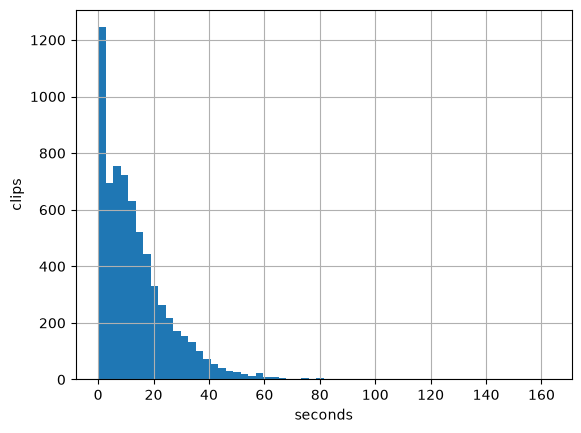

total hours: 25.799030555555554


In [18]:
print("Plot of Duration of each row/audio:-")
df["duration"] = df["end_time"] - df["start_time"]
display(df["duration"].describe())
df["duration"].hist(bins=60)
plt.xlabel("seconds"); plt.ylabel("clips"); plt.show()
print("total hours:", df["duration"].sum() / 3600)   # about 25.8

In [ ]:
_open_files = {}

def load_audio(row):
    """Return (waveform, sample_rate) for one row of df."""
    path = A_DIR / row["split"] / row["file"]
    if path not in _open_files:
        _open_files[path] = pq.ParquetFile(path)
    pf = _open_files[path]
    start = 0
    for g in range(pf.num_row_groups):
        n = pf.metadata.row_group(g).num_rows
        if row["row_in_file"] < start + n:
            tbl = pf.read_row_group(g, columns=["audio"])
            wav_bytes = tbl.column("audio")[row["row_in_file"] - start].as_py()["bytes"]
            return sf.read(io.BytesIO(wav_bytes))
        start += n
    raise IndexError("row not found")

audio_id : A202504061041141896300222303337
speaker  : likhabai1830_22085 | Male 18-30
duration : 11.14 s   sample rate: 16000
IPA      : ho ŋul bepjəm ho akʔ boluho lele namə ŋul bɛpjaːm d̪əd̪ub la hogə ŋul market̪ ho ɲɪd̪ub kəm ŋul leled̪ən


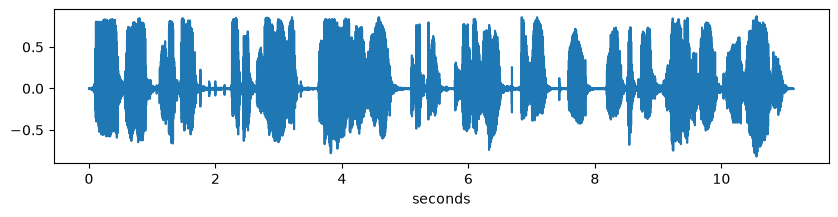

In [21]:
# read a transcript with waveform
row = df.sample(1, random_state=3).iloc[0]
y, sr = load_audio(row)

print("audio_id :", row["audio_id"])
print("speaker  :", row["speakerId"], "|", row["speaker1-gender"], row["speaker1-ageGroup"])
print("duration :", round(len(y) / sr, 2), "s   sample rate:", sr)
print("IPA      :", row[T])
display(Audio(y, rate=sr))

plt.figure(figsize=(10, 2))
plt.plot(np.arange(len(y)) / sr, y)
plt.xlabel("seconds"); plt.show()

In [24]:
print("Listen to more audios, one after another:-")
sample = df[~missing].sample(10, random_state=7)
for _, row in sample.iterrows():
    y, sr = load_audio(row)
    print(f"{row['audio_id']}  |  {len(y)/sr:.1f}s  |  {row['speakerId']}")
    print(row[T])
    display(Audio(y, rate=sr))
    print("-" * 80)

Listen to more audios, one after another:-
A20241123124822350278-slice00030094701410  |  4.6s  |  hiniummama1830_20241123124546104448
hoge skul karati pa məɲaŋ gemdoɲi apa


--------------------------------------------------------------------------------
A20241121124823635517-slice00001331013697  |  3.9s  |  ichikopito1830_20241121122023725412
ɔgʌ mikfʔ iːmfɔrtʌn iːmfɔrtʌn kueʃʌnaːŋul het̪ʌn iːjɪm


--------------------------------------------------------------------------------
A202504181517077398570004501218  |  11.7s  |  lishiaku1830_22088
ŋame name istjuːdnt tuluŋəm sʌɪənsəm hoɡəb poraiden habalokəm mule aʔɡe ajakəm cendub mule sʌɪənsəm mul pordenla


--------------------------------------------------------------------------------
A20241123124822350278-slice00060633206977  |  6.5s  |  hiniummama1830_20241123124546104448
ŋul res kam paiŋ mədəna aje gubri ɟa


--------------------------------------------------------------------------------
A20250610092209738599  |  32.9s  |  likhabai1830_22085
ŋul gə naːm pɪngə d̪eblɔpment̪ kəmɪt̪iː gə ljiːnamə ŋul gə nam pɪn ho hiːje niːŋə ɔk aːs aːj aːd̪ən ham kat̪əl ho hogo nampoŋə hogo roluŋə ɪʃc lagd̪o ho pʰam ɪs ɟɪd̪ub həb maːb d̪ɪ hogo lam pjaːŋa aːl kuma ho lam pja ɟɪd̪ub hogə gorment̪ ɪskiːmə je niː xab happən ho niːŋəm ɟɪʒ d̪ub ɟɪn aːp d̪ub həb d̪ub ŋul gə bɪleɟ d̪eblɔp kəmɪt̪iːŋə d̪od̪ən


--------------------------------------------------------------------------------
A202506100939175959010007200542  |  4.7s  |  jorampaul1830_22526
a betam durima hab ɟakam bentam tajin  ije


--------------------------------------------------------------------------------
A20241121134208844726-slice00020877710343  |  15.7s  |  joramtapu4560_20241121134050992829
ma hu ŋulo atu siɟa moce bula mədəŋ ŋulo ɟiɟu kap  məimin so olo bota pitiok bɯitel ie de mɯimin soman  sib soman


--------------------------------------------------------------------------------
A20241121142431394819-slice00000287303426  |  5.5s  |  dobiamaniya3045_20241121141257651534
am sevintin hoga ije ŋo si solo toenti for naŋom dodo den


--------------------------------------------------------------------------------
A202506100925330421620079900860  |  0.6s  |  tajjarbo3045_22561
ald̪ou


--------------------------------------------------------------------------------
A20241122184502824208-slice00020046903063  |  25.9s  |  likharich4560_20241120151509865815
ɔ siː naŋul kəl kɛl pobu kel pobul ŋul soɟan bend̪ən ŋul gə siː kəl pɔ ŋuŋə siː paja pobuŋə aː sɪ pasa pobuŋə t̪e paja pobuŋə hɔgə siː alo kəl pobu həl bela ɛl ŋul so səm jəma t̪əd̪aje jema t̪əd̪ajo d̪al bem pənana pəsa pasa bele sət̪əl pəsa nampɪn sət̪əl oŋulə jema t̪ed̪a həl bemp na


--------------------------------------------------------------------------------


In [28]:
print("check that the audio matches the stated duration.\nIt prints only the clips whose real length differs from end_time − start_time by more than 0.05 s. On a random 30 you’ll usually see none")
chk = df.sample(30, random_state=5)
for _, row in chk.iterrows():
    y, sr = load_audio(row)
    diff = len(y) / sr - row["duration"]
    if abs(diff) > 0.05:
        print(row["audio_id"], "stated", round(row["duration"], 2), "actual", round(len(y) / sr, 2))
print("done")

check that the audio matches the stated duration.
It prints only the clips whose real length differs from end_time − start_time by more than 0.05 s. On a random 30 you’ll usually see none
done


In [31]:
print("one row per publicSpeakerId")
spk = df.groupby("publicSpeakerId").agg(
    rows=("audio_id", "size"),
    hours=("duration", lambda x: round(x.sum() / 3600, 3)),
    n_speakerId=("speakerId", "nunique"),
    genders=("speaker1-gender", lambda x: " | ".join(sorted(x.unique()))),
    ages=("speaker1-ageGroup", lambda x: " | ".join(sorted(x.unique()))),
).sort_values("hours", ascending=False)

print("speakers:", len(spk))                       # expect 60
spk.head(15)

one row per publicSpeakerId
speakers: 60


,rows,hours,n_speakerId,genders,ages
publicSpeakerId,,,,,
6867765bff16e00b68f4bba0,985,5.468,1,Female,18-30
699b255a30cac07f2bf9281d,905,4.328,1,Male,18-30
6867765bff16e00b68f4bba8,643,4.015,1,Female,18-30
6867765bff16e00b68f4bba4,370,1.022,1,Female,18-30
6867765bff16e00b68f4bba2,383,0.992,1,Male,18-30
6741d0cb208b312091ae7fc0,107,0.879,1,Male,45-60
6867765bff16e00b68f4bba6,238,0.872,1,Male,18-30
673f2605647c6d6bf3fd834a,83,0.811,1,Female,30-45
673f3951ecea429b81f3a160,158,0.738,1,Male,60+


In [38]:
print("Which speakers have conflicting information")
bad = spk[(spk["n_speakerId"] > 1)
          | spk["genders"].str.contains("|", regex=False)
          | spk["ages"].str.contains("|", regex=False)]
print("speakers with a conflict:", len(bad))      # expect 4
bad

Which speakers have conflicting information
speakers with a conflict: 4


,rows,hours,n_speakerId,genders,ages
publicSpeakerId,,,,,
6741913a208b312091ae7a04,92,0.279,3,Female | Male,45-60
673f37a6554540458864b505,37,0.137,3,Female,30-45 | 45-60
673f37e516ece267dd18bfd4,36,0.093,3,Female,30-45 | 45-60
6741f7b68a00b24987714f43,11,0.008,2,Female | Male,45-60


In [ ]:
rev = df.groupby("speakerId")["publicSpeakerId"].nunique()
print("speakerIds that map to more than one publicSpeakerId:", (rev > 1).sum())   # expect 5
rev[rev > 1]

speakerIds that map to more than one publicSpeakerId: 5


speakerId
['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']    2
joramjyoti4560_20241123082426492592                                             2
joramyano4560_20241123154142271479                                              2
pachurinya4560_20241121133845251489                                             2
totosuka3045_20241121133742174580                                               2
Name: publicSpeakerId, dtype: int64

In [39]:
print("Metadata for each conflicting grp")
conf_ids = rev[rev > 1].index
conf = df[df["speakerId"].isin(conf_ids)]
print("rows involved:", len(conf), "| hours:", round(conf["duration"].sum() / 3600, 3))

conf.groupby(["speakerId", "publicSpeakerId"]).agg(
    rows=("audio_id", "size"),
    hours=("duration", lambda x: round(x.sum() / 3600, 3)),
    gender=("speaker1-gender", lambda x: " | ".join(sorted(x.unique()))),
    age=("speaker1-ageGroup", lambda x: " | ".join(sorted(x.unique()))),
    place=("speaker1-placeOfRecording", lambda x: " | ".join(sorted(x.unique()))),
    spk2_gender=("speaker2-gender", lambda x: " | ".join(sorted(x.unique()))),
    splits=("split", lambda x: " | ".join(sorted(x.unique()))),
    sessions=("sentenceId", lambda x: x.str.split("_").str[0].nunique()),
)
print("play a few clips from each grp")
def play_group(speaker_id, public_id, n=3, seed=0, min_s=2, max_s=15):
    sub = df[(df["speakerId"] == speaker_id) & (df["publicSpeakerId"] == public_id)]
    sub = sub[(sub["duration"] >= min_s) & (sub["duration"] <= max_s) & (sub[T].str.strip() != "N/A")]
    print("=" * 90)
    print("speakerId       :", speaker_id)
    print("publicSpeakerId :", public_id, f"  ({len(sub)} clips of 2-15 s with a transcript)")
    for _, row in sub.sample(min(n, len(sub)), random_state=seed).iterrows():
        y, sr = load_audio(row)
        print("-" * 90)
        print(f"{row['audio_id']} | {len(y)/sr:.1f}s | {row['split']} | "
              f"{row['speaker1-gender']} {row['speaker1-ageGroup']} | place: {row['speaker1-placeOfRecording']} | "
              f"speaker2: {row['speaker2-gender']} {row['speaker2-ageGroup']}")
        print("domain:", row["Domain"], "| Q_Id:", row["Q_Id"])
        print("IPA   :", row[T])
        display(Audio(y, rate=sr))
pairs = (conf.groupby(["speakerId", "publicSpeakerId"]).size().reset_index()[["speakerId", "publicSpeakerId"]])
for _, p in pairs.iterrows():
    play_group(p["speakerId"], p["publicSpeakerId"], n=3)


tiny = conf[conf["speakerId"].str.startswith("[")]
print(len(tiny), "rows")
tiny[["audio_id", "speakerId", "publicSpeakerId", "duration", "speaker1-gender", "speaker2-gender", T]]
for _, row in tiny.iterrows():
    y, sr = load_audio(row)
    print(row["audio_id"], f"| {len(y)/sr:.1f}s |", row["publicSpeakerId"])
    print(row[T])
    display(Audio(y, rate=sr))


Metadata for each conflicting grp
rows involved: 175 | hours: 0.516
play a few clips from each grp
speakerId       : ['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']
publicSpeakerId : 673f37a6554540458864b505   (7 clips of 2-15 s with a transcript)
------------------------------------------------------------------------------------------
A20241123095330995958-slice00020499506473 | 14.8s | validation | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : dohedo mulɡe uso dosdena naŋe dukane sirikiro sanmadomae niŋa aikəm hara dos bis toka ɡoto ara lopoja jadke oŋultudo aləm hebijet dopa tulu dodo odonjete uljumdedko


------------------------------------------------------------------------------------------
A20241123095330995958-slice00011008310585 | 5.0s | train | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : buinka ɟao uɡɟaɡaŋe labjoka aen makal besdo ɡid̪a akbent̪amsadena


------------------------------------------------------------------------------------------
A20241123095330995958-slice00010907909785 | 7.1s | train | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : a eɲe kaɟa oɡalabe ɡid̪a akbe bencte cemala t̪aderma uɡalasele nomiɡabde mameɡabmaŋɔ


speakerId       : ['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']
publicSpeakerId : 673f37e516ece267dd18bfd4   (3 clips of 2-15 s with a transcript)
------------------------------------------------------------------------------------------
A20241123095330995958-slice00020404504905 | 8.6s | train | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : ŋake kakəm utɡot̪adodo aŋkəmlo lise bat̪a nalise ecubɡoɡo aməm kamlo linmat̪ake


------------------------------------------------------------------------------------------
A20241123095330995958-slice00020258203638 | 10.6s | train | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : bule ekiɡo etkaləm pinɡo ɲakəm ɲakəm mana ɲakəm mud̪a muibo solo səːvɪs liɟot̪abɯden roŋɔ uɟo t̪abe a roŋɔ


------------------------------------------------------------------------------------------
A20241123095330995958-slice00010981010037 | 2.3s | train | Female 30-45 | place: Yachuli | speaker2: N/A N/A
domain: N/A | Q_Id: N/A
IPA   : muldit̪acinlijama muɡabma


... (23 outputs left out)

A20241123095330995958-slice00020258203638 | 10.6s | 673f37e516ece267dd18bfd4
bule ekiɡo etkaləm pinɡo ɲakəm ɲakəm mana ɲakəm mud̪a muibo solo səːvɪs liɟot̪abɯden roŋɔ uɟo t̪abe a roŋɔ


A20241123095330995958-slice00020404504905 | 8.6s | 673f37e516ece267dd18bfd4
ŋake kakəm utɡot̪adodo aŋkəmlo lise bat̪a nalise ecubɡoɡo aməm kamlo linmat̪ake


A20241123095208806033-slice00020405005484 | 14.3s | 673f37a6554540458864b505
həm həmte baɲokəm o bud̪a loko kuhɲakəm obule cent̪ai huhɲakəm matlab eiɟ eiɟ balana kuhɲakəm tu tuloŋəm t̪aka laɡiboŋ mule jocijoma


A20241123095330995958-slice00020499506473 | 14.8s | 673f37a6554540458864b505
dohedo mulɡe uso dosdena naŋe dukane sirikiro sanmadomae niŋa aikəm hara dos bis toka ɡoto ara lopoja jadke oŋultudo aləm hebijet dopa tulu dodo odonjete uljumdedko


In [34]:
multi = df[df["speakerId"].str.contains("and", regex=False) | df["speakerId"].str.startswith("[")]
multi.groupby(["speakerId", "publicSpeakerId"]).agg(
    rows=("audio_id", "size"),
    hours=("duration", lambda x: round(x.sum() / 3600, 3)))

rows  hours
speakerId                                                                     publicSpeakerId                      
['joramjyoti4560_20241123082426492592', 'joramyano4560_20241123154142271479'] 6741913a208b312091ae7a04     1  0.000
['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']  673f37a6554540458864b505     7  0.015
                                                                              673f37e516ece267dd18bfd4     3  0.006
joramainaandjoramdui3045_20241122123435431579                                 67407a5b16ece267dd18bfd6    22  0.040
joramnamaandnabamrunaya3045_20241121132314843591                              673f34421f106fded16408cc    32  0.043
joramnikamandjoramchobin4560_20241121132620910720                             673f34fc554540458864b504    89  0.311
jorampaulandjoramyama000_20241121133402905857                                 673f36ca0984e3815daab2af    65  0.048

In [35]:
df["id_age_code"] = df["speakerId"].str.extract(r"(\d{3,4})_\d+")[0]
pd.crosstab(df["id_age_code"].fillna("none"), df["speaker1-ageGroup"])

speaker1-ageGroup,18-30,30-45,45-60,60+,N/A
id_age_code,,,,,
000,0,0,0,0,65
1830,4184,0,0,0,0
3045,0,1573,0,0,0
4560,0,0,688,0,0
none,0,0,0,208,0


In [36]:
df["session"] = df["sentenceId"].str.split("_").str[0]
df["session_noslice"] = df["session"].str.replace(r"-slice\d+$", "", regex=True)

print("with slice number   :", df["session"].nunique())          # expect 2660
print("without slice number:", df["session_noslice"].nunique())  # expect 2333

# how many speakers per session?
df.groupby("session_noslice")["publicSpeakerId"].nunique().value_counts()

with slice number   : 2660
without slice number: 2333


publicSpeakerId
1    2329
2       4
Name: count, dtype: int64

In [37]:
s2 = df[df["speaker2-gender"] != "N/A"]
print("rows with speaker 2 info:", len(s2))                       # expect 11
s2[["speakerId", "publicSpeakerId", "speaker1-gender", "speaker2-gender", "speaker2-ageGroup"]].drop_duplicates()

rows with speaker 2 info: 11


,speakerId,publicSpeakerId,speaker1-gender,speaker2-gender,speaker2-ageGroup
4747,totosuka3045_20241121133742174580,673f37a6554540458864b505,Female,Female,45-60
4775,pachurinya4560_20241121133845251489,673f37e516ece267dd18bfd4,Female,Female,45-60
4882,joramyano4560_20241123154142271479,6741f7b68a00b24987714f43,Male,Male,45-60


In [40]:
print("=" * 100)
print("CELL M1 - SPEAKER STATUS: which speakers can we trust, and which must stay in train only?")
print("=" * 100)

# One row per publicSpeakerId, with three facts about each:
#   n_speakerId : how many different raw speakerId strings point to this public ID
#   genders     : every distinct gender label found for this public ID, joined with " | "
#   ages        : every distinct age-group label found for this public ID, joined with " | "
spk = df.groupby("publicSpeakerId").agg(
    n_speakerId=("speakerId", "nunique"),
    genders=("speaker1-gender", lambda x: " | ".join(sorted(x.unique()))),
    ages=("speaker1-ageGroup", lambda x: " | ".join(sorted(x.unique()))),
)

# A public ID is "in conflict" if ANY of these is true:
#   - it is linked to more than one raw speakerId
#   - it has more than one gender label (the " | " separator appears in the text)
#   - it has more than one age-group label
conflict_ids = set(spk[(spk["n_speakerId"] > 1)
                       | spk["genders"].str.contains("|", regex=False)
                       | spk["ages"].str.contains("|", regex=False)].index)

# A "pair recording" is a row whose raw speakerId names two people:
#   - "X and Y" style IDs contain the text "and"
#   - the other style is a list written in square brackets, starting with "["
is_pair_recording = df["speakerId"].str.contains("and", regex=False) | df["speakerId"].str.startswith("[")

# Final label for every row, in priority order:
#   1) public ID is one of the conflicting ones -> "uncertain_identity"
#   2) otherwise, a pair recording               -> "multi_person"
#   3) everything else                           -> "ok"
status = np.where(df["publicSpeakerId"].isin(conflict_ids), "uncertain_identity",
         np.where(is_pair_recording, "multi_person", "ok"))

print(f"\nPublic speaker IDs found in the dataset: {len(spk)}   (expected 60)")
print(f"Public IDs flagged as conflicting      : {len(conflict_ids)}   (expected 4)")
print(f"Rows that belong to a pair recording    : {int(is_pair_recording.sum())}")
print("\nNumber of ROWS (audio clips) in each speaker_status class")
print("(expected: ok 6334, multi_person 208, uncertain_identity 176):\n")
print(pd.Series(status).value_counts().to_string())

CELL M1 - SPEAKER STATUS: which speakers can we trust, and which must stay in train only?

Public speaker IDs found in the dataset: 60   (expected 60)
Public IDs flagged as conflicting      : 4   (expected 4)
Rows that belong to a pair recording    : 219

Number of ROWS (audio clips) in each speaker_status class
(expected: ok 6334, multi_person 208, uncertain_identity 176):

ok                    6334
multi_person           208
uncertain_identity     176


In [41]:
print("=" * 100)
print("CELL M2 - BUILD THE MASTER TABLE: one row per original audio clip, with our own clean columns")
print("=" * 100)

def clean(s):
    """Replace the dataset's text placeholders ('N/A', empty, 'nan', 'None') by a real empty value.
    Used ONLY for metadata columns; the transcript itself is never touched."""
    return s.where(~s.astype(str).str.strip().isin(["N/A", "", "nan", "None"]), None)

M = pd.DataFrame({
    # ---- identity of the clip ----
    "sample_id": ["A_" + str(i + 1).zfill(6) for i in range(len(df))],   # our own ID: A_000001 ... A_006718
    "source_dataset": "Narration",                                         # which dataset this row belongs to
    "original_audio_id": df["audio_id"],                                   # the dataset's own ID, unchanged
    "audio_path": "raw/A_narration/data/" + df["split"] + "/" + df["file"] + "#row=" + df["row_in_file"].astype(str),
                                                                           # where the audio lives: parquet file + row number
    "original_split": df["split"],                                         # train / validation / test as the authors had it
    # ---- timing ----
    "start_time": df["start_time"],                                        # segment start inside the longer recording (s)
    "end_time": df["end_time"],                                            # segment end inside the longer recording (s)
    "duration_seconds": (df["end_time"] - df["start_time"]).round(3),      # clip length, computed from the two above
    "duration_basis": "stated (end_time - start_time)",                    # reminder: not yet checked by decoding every file
    # ---- transcript ----
    "transcript_raw": df[T],                                               # the IPA text exactly as given - never edited
    "transcript_missing": df[T].str.strip().isin(["N/A", ""]),             # True when the transcript is a placeholder
    "transcript_normalized": None,                                         # empty for now; filled in Step 4
    # ---- speaker ----
    "speaker_id": df["publicSpeakerId"],                                   # the speaker key we use from now on
    "speaker_id_raw": df["speakerId"],                                     # the original raw speakerId, kept for reference
    "speaker_status": status,                                              # ok / uncertain_identity / multi_person (from M1)
    "is_pair_recording": is_pair_recording,                                # True when the raw ID names two people
    "train_only": status != "ok",                                          # True = this row may only go to the train split
    # ---- recording info ----
    "recording_session_id": df["sentenceId"].str.split("_").str[0].str.replace(r"-slice\d+$", "", regex=True),
                                                                           # sentenceId before "_", minus "-sliceNNNN" = one original recording
    "sentence_id": df["sentenceId"],
    "boundary_id": df["boundaryID"],
    "filename": df["filename"],
    # ---- prompt and speaker metadata (placeholders turned into empty values) ----
    "domain": clean(df["Domain"]),
    "elicitation_method": clean(df["Elicitation Method"]),
    "q_id": clean(df["Q_Id"]),
    "gender": clean(df["speaker1-gender"]),
    "age_group": clean(df["speaker1-ageGroup"]),
    "education_level": clean(df["speaker1-educationLevel"]),
    "place_of_recording": clean(df["speaker1-placeOfRecording"]),
    "type_of_place": clean(df["speaker1-typeOfPlace"]),
    "other_languages": clean(df["speaker1-otherLanguages-list"]),
    "speaker2_gender": clean(df["speaker2-gender"]),
    "speaker2_age_group": clean(df["speaker2-ageGroup"]),
    # ---- columns that later steps will fill in (empty for now) ----
    "quality_status": None, "exclusion_reason": None,
    "transcript_review_status": "not_reviewed",
    "language_status": None, "content_type": "narration",
    "duplicate_group_id": None, "final_split": None,
})

print(f"\nMaster table built: {M.shape[0]} rows x {M.shape[1]} columns   (expected 6718 x 39)")
print("\nFirst 5 rows of the master table (scroll right to see all columns):")
display(M.head())

CELL M2 - BUILD THE MASTER TABLE: one row per original audio clip, with our own clean columns

Master table built: 6718 rows x 39 columns   (expected 6718 x 39)

First 5 rows of the master table (scroll right to see all columns):


,sample_id,source_dataset,original_audio_id,audio_path,original_split,start_time,end_time,duration_seconds,duration_basis,transcript_raw,transcript_missing,transcript_normalized,speaker_id,speaker_id_raw,speaker_status,is_pair_recording,train_only,recording_session_id,sentence_id,boundary_id,filename,domain,elicitation_method,q_id,gender,age_group,education_level,place_of_recording,type_of_place,other_languages,speaker2_gender,speaker2_age_group,quality_status,exclusion_reason,transcript_review_status,language_status,content_type,duplicate_group_id,final_split
0,A_000001,Narration,A202506100851377938950011700557,raw/A_narration/data/test/data-083f238c.parquet#row=0,test,1.17,5.57,4.40,stated (end_time - start_time),mitun ham ŋun ɲokɯm pestibal holo sekripraiɟ malai deden,False,None,6867765bff16e00b68f4bba2,jorampaul1830_22526,ok,False,False,A20250610085137793895,A20250610085137793895_0011700557,0011700557,T-6909.MT-3438357.MTA-4866ccc4ec5e41f4bffb830cb69abda3.A-562950053594623.W-22526.K-OutputRecording.R-9b33f02a968ba25...,Agriculture,Narration,AG_206,Male,18-30,NaN,NaN,NaN,NaN,NaN,NaN,None,None,not_reviewed,None,narration,None,None
1,A_000002,Narration,A202506100917530835240169702776,raw/A_narration/data/test/data-083f238c.parquet#row=1,test,16.97,27.76,10.79,stated (end_time - start_time),ta bialak bendən ɲisi gon boʃi nimʃi alba koisənam beŋka təna səm səmɟidup ta beana bendup pəca,False,None,6867765bff16e00b68f4bba2,jorampaul1830_22526,ok,False,False,A20250610091753083524,A20250610091753083524_0169702776,0169702776,T-6925.MT-3442912.MTA-a4f04d4d21e647fc9923888ac95ecc29.A-562950053594643.W-22526.K-OutputRecording.R-9b0e590880dffc2...,Culture,Narration,CLT_20,Male,18-30,NaN,NaN,NaN,NaN,NaN,NaN,None,None,not_reviewed,None,narration,None,None
2,A_000003,Narration,A202506100939571642100099801600,raw/A_narration/data/test/data-083f238c.parquet#row=2,test,9.98,16.00,6.02,stated (end_time - start_time),promi pori mabol ene biri sigret pilajel gomiŋam ugub ŋun ge dimag matael iː,False,None,6867765bff16e00b68f4bba2,jorampaul1830_22526,ok,False,False,A20250610093957164210,A20250610093957164210_0099801600,0099801600,T-6926.MT-3442931.MTA-0547c91984b64d4e9d5947a0dac2597e.A-562950053594656.W-22526.K-OutputRecording.R-84ac724f61b22cb...,Education,Narration,ED-08,Male,18-30,NaN,NaN,NaN,NaN,NaN,NaN,None,None,not_reviewed,None,narration,None,None
3,A_000004,Narration,A20250805170539197219,raw/A_narration/data/test/data-083f238c.parquet#row=3,test,0.68,24.49,23.81,stated (end_time - start_time),gariŋam cabi aləktəl eksiletaram gabuktəl klacam gabuktəl giaram aləktəl ene e parbin suma bo ene en giaram utaitel ...,False,None,6867765bff16e00b68f4bba2,jorampaul1830_22526,ok,False,False,A20250805170539197219,A20250805170539197219_0006802449,0006802449,T-6930.MT-3443233.MTA-8b0f069bf83e4c7c8faa521e4a373d04.A-562950053594706.W-22526.K-OutputRecording.R-a640ad53fc03a10...,Science-Technology,Narration,ST_96,Male,18-30,NaN,NaN,NaN,NaN,NaN,NaN,None,None,not_reviewed,None,narration,None,None
4,A_000005,Narration,A202506100930173563760112002477,raw/A_narration/data/test/data-083f238c.parquet#row=4,test,11.20,24.77,13.57,stated (end_time - start_time),uɡlu mahesiɟa liɟakəm nətɪs lencot̪ai holit̪ai hebnel ɟaha t̪aha liɡu likma ho ɛdjʊkeɪʃn dolail kulsiɟan nətɪshe nai...,False,None,6867765bff16e00b68f4bba4,likhaaku1830_23032,ok,False,False,A20250610093017356376,A20250610093017356376_0112002477,0112002477,T-6926.MT-3442943.MTA-f0b7464901e744b09dd761ec141eb663.A-562950053661061.W-23032.K-OutputRecording.R-b79b109537217da...,Education,Narration,ED-20,Female,18-30,NaN,NaN,NaN,NaN,NaN,NaN,None,None,not_reviewed,None,narration,None,None


In [42]:
print("=" * 100)
print("CELL M3 - CHECKS: is the master table complete, unique and consistent with what we know?")
print("=" * 100)

# These two lines STOP the notebook with an error if something is wrong.
assert len(M) == 6718, "row count is not 6718"
assert M["sample_id"].is_unique and M["original_audio_id"].is_unique, "duplicate IDs found"
print("\n[OK] 6718 rows, every sample_id and every original_audio_id is unique.")
print(f"\nTotal duration of all clips: {round(M['duration_seconds'].sum() / 3600, 3)} hours   (expected 25.799)")

print("\n--- TABLE 1: size of each speaker_status class ---")
print("rows = clips, speakers = distinct speaker_id values, hours = total audio")
print("(expected: ok 52 speakers / 24.84 h; multi_person 4 / 0.44 h; uncertain_identity 4 / 0.52 h)")
display(M.groupby("speaker_status").agg(
    rows=("sample_id", "size"),
    speakers=("speaker_id", "nunique"),
    hours=("duration_seconds", lambda x: round(x.sum() / 3600, 3))))

print("\n--- TABLE 2: speaker_status by the authors' ORIGINAL split ---")
print("shows how many flagged clips the authors had put into test/validation (we will keep them out of there later)")
display(M.groupby(["original_split", "speaker_status"]).size().unstack(fill_value=0))

print("\n--- TABLE 3: which raw speakerId strings are flagged, and how many clips each ---")
display(M[M["speaker_status"] != "ok"].groupby(["speaker_status", "speaker_id_raw"]).size().rename("clips"))

CELL M3 - CHECKS: is the master table complete, unique and consistent with what we know?

[OK] 6718 rows, every sample_id and every original_audio_id is unique.

Total duration of all clips: 25.799 hours   (expected 25.799)

--- TABLE 1: size of each speaker_status class ---
rows = clips, speakers = distinct speaker_id values, hours = total audio
(expected: ok 52 speakers / 24.84 h; multi_person 4 / 0.44 h; uncertain_identity 4 / 0.52 h)


,rows,speakers,hours
speaker_status,,,
multi_person,208,4,0.442
ok,6334,52,24.841
uncertain_identity,176,4,0.516



--- TABLE 2: speaker_status by the authors' ORIGINAL split ---
shows how many flagged clips the authors had put into test/validation (we will keep them out of there later)


speaker_status,multi_person,ok,uncertain_identity
original_split,,,
test,20,645,19
train,166,5002,137
validation,22,687,20



--- TABLE 3: which raw speakerId strings are flagged, and how many clips each ---


speaker_status      speaker_id_raw                                                               
multi_person        joramainaandjoramdui3045_20241122123435431579                                    22
                    joramnamaandnabamrunaya3045_20241121132314843591                                 32
                    joramnikamandjoramchobin4560_20241121132620910720                                89
                    jorampaulandjoramyama000_20241121133402905857                                    65
uncertain_identity  ['joramjyoti4560_20241123082426492592', 'joramyano4560_20241123154142271479']     1
                    ['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']     10
                    joramjyoti4560_20241123082426492592                                              92
                    joramyano4560_20241123154142271479                                               10
                    pachurinya4560_20241121133845251489               

In [44]:
print("=" * 100)
print("CELL M4 - TRACE-BACK TEST: does each master row really point to the right raw audio/transcript?")
print("=" * 100)
print("We pick 5 random rows, open the raw parquet file named in audio_path, go to the stated row,")
print("and compare the audio_id and the transcript with what the master table says.\n")

chk = M.sample(5, random_state=11)
for _, r in chk.iterrows():
    path, row_n = r["audio_path"].split("#row=")                            # split "file#row=17" into file and row number
    t = pq.ParquetFile(ROOT / path).read(columns=[T, "audio_id"]).to_pandas().iloc[int(row_n)]   # read that row from the raw file
    print(r["sample_id"], "| audio_id match:", t["audio_id"] == r["original_audio_id"],
          "| transcript match:", t[T] == r["transcript_raw"])


CELL M4 - TRACE-BACK TEST: does each master row really point to the right raw audio/transcript?
We pick 5 random rows, open the raw parquet file named in audio_path, go to the stated row,
and compare the audio_id and the transcript with what the master table says.

A_004317 | audio_id match: True | transcript match: True
A_002696 | audio_id match: True | transcript match: True
A_002089 | audio_id match: True | transcript match: True
A_001633 | audio_id match: True | transcript match: True
A_002072 | audio_id match: True | transcript match: True


In [45]:
print("=" * 100)
print("CELL M5 - SAVE the master table to disk (two formats)")
print("=" * 100)

OUT = ROOT / "manifests"                      # folder for tables we create
OUT.mkdir(exist_ok=True)                      # create it if it does not exist yet
M.to_parquet(OUT / "master_A.parquet", index=False)                    # compact, exact; used by later code
M.to_csv(OUT / "master_A.csv", index=False, encoding="utf-8-sig")      # readable in Excel (utf-8-sig keeps the IPA symbols correct)

back = pd.read_parquet(OUT / "master_A.parquet")                       # read it back to prove the saved file is intact
print(f"\nSaved to: {OUT}")
print(f"Reloaded file shape: {back.shape}   (expected (6718, 39))")
print("Transcripts identical after saving and reloading:", back["transcript_raw"].equals(M["transcript_raw"]), "  (expected True)")

CELL M5 - SAVE the master table to disk (two formats)

Saved to: C:\Users\Kanchan Potdar\Downloads\BTP\manifests
Reloaded file shape: (6718, 39)   (expected (6718, 39))
Transcripts identical after saving and reloading: True   (expected True)


In [46]:
print("=" * 100)
print("CELL M6 - DECISION LOG: write down every decision made in Step 3, so it can be cited in the thesis")
print("=" * 100)
import csv, datetime
today = datetime.date.today().isoformat()
st = M.groupby("speaker_status").agg(rows=("sample_id", "size"), hours=("duration_seconds", lambda x: round(x.sum() / 3600, 3)))

# each list = [date, step, decision, reason, rows affected, hours affected]
log = [
 [today, "3", "Narration speaker key = publicSpeakerId (60 speakers)", "More consistent than speakerId (62 values, pair recordings)", len(M), round(M["duration_seconds"].sum()/3600, 3)],
 [today, "3", "speaker_status=uncertain_identity for the 4 conflicting public IDs; train_only", "gender/age or several speakerIds per public ID", int(st.loc["uncertain_identity","rows"]), float(st.loc["uncertain_identity","hours"])],
 [today, "3", "speaker_status=multi_person for pair recordings ('X and Y'); train_only", "voice cannot be attributed to one speaker", int(st.loc["multi_person","rows"]), float(st.loc["multi_person","hours"])],
 [today, "3", "session id = sentenceId prefix without -sliceNNNN (2333 sessions)", "slice number is a piece of one recording", len(M), None],
 [today, "3", "duration = end_time - start_time (stated, not yet decoded)", "decoded check on 30 random clips matched; full check is Step 11", len(M), None],
]
with open(OUT / "decision_log_A.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["date", "step", "decision", "reason", "rows_affected", "hours_affected"])   # column headings
    w.writerows(log)                                                                          # one line per decision
print(f"\nDecision log saved to: {OUT / 'decision_log_A.csv'}")
print("Its content (one row per decision; add a new row every time you make a cleaning decision in later steps):")
display(pd.read_csv(OUT / "decision_log_A.csv"))

CELL M6 - DECISION LOG: write down every decision made in Step 3, so it can be cited in the thesis

Decision log saved to: C:\Users\Kanchan Potdar\Downloads\BTP\manifests\decision_log_A.csv
Its content (one row per decision; add a new row every time you make a cleaning decision in later steps):


,date,step,decision,reason,rows_affected,hours_affected
0,2026-10-11,3,Narration speaker key = publicSpeakerId (60 speakers),"More consistent than speakerId (62 values, pair recordings)",6718,25.799
1,2026-10-11,3,speaker_status=uncertain_identity for the 4 conflicting public IDs; train_only,gender/age or several speakerIds per public ID,176,0.516
2,2026-10-11,3,speaker_status=multi_person for pair recordings ('X and Y'); train_only,voice cannot be attributed to one speaker,208,0.442
3,2026-10-11,3,session id = sentenceId prefix without -sliceNNNN (2333 sessions),slice number is a piece of one recording,6718,NaN
4,2026-10-11,3,"duration = end_time - start_time (stated, not yet decoded)",decoded check on 30 random clips matched; full check is Step 11,6718,NaN


In [48]:
print("=" * 100)
print("CELL M7 (optional) - SPEAKERS WHOSE NAME ALSO APPEARS IN A PAIR RECORDING")
print("=" * 100)
print("This does NOT change the master table. It only lists speakers marked 'ok' whose name stem")
print("(the name part of the raw speakerId) also appears in a pair recording. If the name means the same person,")
print("this person's voice would be in both train (pair recording) and, possibly, test (as a solo speaker) = leakage.\n")
import re

def stems(r):
    """Return the list of name stems inside a raw speakerId.
       '[..]' style  -> every 'name+digits_digits' piece found inside the brackets
       'XandY' style -> the two names split on 'and'
       normal style  -> the single name (trailing digits and timestamp removed)"""
    if r.startswith("["):
        return re.findall(r"([a-z]+)\d+_\d+", r)
    base = re.sub(r"\d+(_\d+)?$", "", r)
    return base.split("and") if "and" in r else [base]

# all name stems that appear in any pair recording
pair_stems = {s for r in M.loc[M["is_pair_recording"], "speaker_id_raw"].unique() for s in stems(r)}
print("Name stems found in pair recordings:", sorted(pair_stems))

# solo rows (not pair recordings) whose single name stem is one of those stems and who are marked ok
solo = M[~M["is_pair_recording"]].copy()
solo["name_stem"] = solo["speaker_id_raw"].map(lambda r: stems(r)[0])
linked = solo[solo["name_stem"].isin(pair_stems) & (solo["speaker_status"] == "ok")]

print("\nSolo speakers marked 'ok' that share a name with a pair-recording participant (expected 3: jorampaul, joramnikam, joramchobin):")
display(linked.groupby(["speaker_id", "speaker_id_raw", "name_stem"]).agg(
    rows=("sample_id", "size"), hours=("duration_seconds", lambda x: round(x.sum() / 3600, 3))))


CELL M7 (optional) - SPEAKERS WHOSE NAME ALSO APPEARS IN A PAIR RECORDING
This does NOT change the master table. It only lists speakers marked 'ok' whose name stem
(the name part of the raw speakerId) also appears in a pair recording. If the name means the same person,
this person's voice would be in both train (pair recording) and, possibly, test (as a solo speaker) = leakage.

Name stems found in pair recordings: ['joramaina', 'joramchobin', 'joramdui', 'joramjyoti', 'joramnama', 'joramnikam', 'jorampaul', 'joramyama', 'joramyano', 'nabamrunaya', 'pachurinya', 'totosuka']

Solo speakers marked 'ok' that share a name with a pair-recording participant (expected 3: jorampaul, joramnikam, joramchobin):


,,,rows,hours
speaker_id,speaker_id_raw,name_stem,,
6741d6128a00b24987714f41,joramchobin4560_20241123131810700209,joramchobin,1,0.000
6867765bff16e00b68f4bba2,jorampaul1830_22526,jorampaul,383,0.992
6867765bff16e00b68f4bba6,joramnikam1830_22536,joramnikam,238,0.872


In [ ]:
# --- load_audio: reads ONE clip's waveform out of the raw parquet file (same function as before) ---
_open_files = {}                                   # remember opened parquet files so we do not reopen them every time
def load_audio(row):
    path = A_DIR / row["split"] / row["file"]      # which parquet file holds this clip
    if path not in _open_files:
        _open_files[path] = pq.ParquetFile(path)
    pf = _open_files[path]
    start = 0
    for g in range(pf.num_row_groups):             # parquet files are cut into blocks ("row groups"); find the block holding our row
        n = pf.metadata.row_group(g).num_rows
        if row["row_in_file"] < start + n:
            tbl = pf.read_row_group(g, columns=["audio"])
            wav_bytes = tbl.column("audio")[row["row_in_file"] - start].as_py()["bytes"]
            return sf.read(io.BytesIO(wav_bytes))  # decode the WAV bytes into (waveform, sample rate)
        start += n

# --- play_clips: plays a few random clips from a group of rows, with the information you need to judge them ---
#   mask  : True/False per row of M, saying which rows belong to the group
#   n     : how many clips to play
#   min_s / max_s : only clips of this length (very short ones are hard to judge by ear)
def play_clips(mask, title, n=4, seed=0, min_s=3, max_s=15):
    sub = M[mask & ~M["transcript_missing"] & (M["duration_seconds"] >= min_s) & (M["duration_seconds"] <= max_s)]
    print("=" * 100)
    print(title)
    print(f"{int(mask.sum())} clips in this group in total; {len(sub)} of them are {min_s}-{max_s} s long and have a transcript; playing {min(n, len(sub))}")
    print("=" * 100)
    for i, r in sub.sample(min(n, len(sub)), random_state=seed).iterrows():
        y, sr = load_audio(df.loc[i])              # df and M have the same row order, so index i finds the same clip in df
        print("-" * 100)
        print(f"{r['sample_id']} | {len(y)/sr:.1f}s | raw speakerId: {r['speaker_id_raw']}")
        print(f"gender/age: {r['gender']} {r['age_group']} | speaker2: {r['speaker2_gender']} {r['speaker2_age_group']} | place: {r['place_of_recording']} | session: {r['recording_session_id']}")
        print("IPA:", r["transcript_raw"])
        display(Audio(y, rate=sr))

In [50]:
from IPython.display import Audio, display
import soundfile as sf

print("METADATA of the speakers compared below")
print("solo = a normal single-speaker recording; PAIR = a recording where two people talk")
print("(gender/age are empty for pair recordings: the dataset did not record them)\n")

# each entry = a True/False mask over the rows of M
grp = {
  "solo  jorampaul":              M["speaker_id_raw"].str.startswith("jorampaul1830"),
  "PAIR  jorampaul+joramyama":    M["speaker_id_raw"].str.startswith("jorampaulandjoramyama"),
  "solo  joramnikam":             M["speaker_id_raw"].str.startswith("joramnikam1830"),
  "PAIR  joramnikam+joramchobin": M["speaker_id_raw"].str.startswith("joramnikamandjoramchobin"),
  "solo  joramchobin":            M["speaker_id_raw"].str.startswith("joramchobin4560"),
}

rows_ = []
for name, m in grp.items():
    s = M[m]
    rows_.append(dict(
        group=name,
        clips=len(s),
        hours=round(s["duration_seconds"].sum() / 3600, 3),
        gender=" | ".join(sorted(s["gender"].dropna().unique())),
        age=" | ".join(sorted(s["age_group"].dropna().unique())),
        place=" | ".join(sorted(s["place_of_recording"].dropna().unique())),
        sessions=s["recording_session_id"].nunique(),          # how many separate recordings this group covers
        first_session=s["recording_session_id"].min()))        # the recording's ID (it starts with the recording date)
display(pd.DataFrame(rows_).set_index("group"))

METADATA of the speakers compared below
solo = a normal single-speaker recording; PAIR = a recording where two people talk
(gender/age are empty for pair recordings: the dataset did not record them)



,clips,hours,gender,age,place,sessions,first_session
group,,,,,,,
solo jorampaul,383,0.992,Male,18-30,,247,A20250418145453326672
PAIR jorampaul+joramyama,65,0.048,,,Yachuli,1,A20241121133445048955
solo joramnikam,238,0.872,Male,18-30,,180,A20250418145726028682
PAIR joramnikam+joramchobin,89,0.311,Male,45-60,Yachuli,1,A20241121132808152109
solo joramchobin,1,0.000,Male,45-60,Yachuli,1,A20241121132808152109


In [52]:
play_clips(grp["solo  jorampaul"], "1a) SOLO speaker: jorampaul (raw ID jorampaul1830_...)", n=3)
play_clips(grp["PAIR  jorampaul+joramyama"], "1b) PAIR recording: jorampaul AND joramyama", n=4)

1a) SOLO speaker: jorampaul (raw ID jorampaul1830_...)
383 clips in this group in total; 290 of them are 3-15 s long and have a transcript; playing 3
----------------------------------------------------------------------------------------------------
A_000808 | 3.6s | raw speakerId: jorampaul1830_22526
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250610091800333400
IPA: ŋokam səbɟi la mana na benamam


----------------------------------------------------------------------------------------------------
A_002387 | 10.2s | raw speakerId: jorampaul1830_22526
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250610085102036652
IPA: kopaŋə kulu kopaŋə dodo kopak kopaŋə dodo ɲissiŋ kopaŋə dodo ɲora kopaŋə dodo hariŋ kopaŋə dodo iccub kopaŋə ɟada dodo


----------------------------------------------------------------------------------------------------
A_003710 | 7.9s | raw speakerId: jorampaul1830_22526
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250610091755328254
IPA: ŋul ge ʈraɖisənal wepen ə a ho benten ho koke  gitisə ma ma gitisə


1b) PAIR recording: jorampaul AND joramyama
65 clips in this group in total; 21 of them are 3-15 s long and have a transcript; playing 4
----------------------------------------------------------------------------------------------------
A_004818 | 3.0s | raw speakerId: jorampaulandjoramyama000_20241121133402905857
gender/age: nan nan | speaker2: nan nan | place: Yachuli | session: A20241121133445048955
IPA: kuʃt̪ə aːj maːs


----------------------------------------------------------------------------------------------------
A_004829 | 7.5s | raw speakerId: jorampaulandjoramyama000_20241121133402905857
gender/age: nan nan | speaker2: nan nan | place: Yachuli | session: A20241121133445048955
IPA: t̪umpəŋo aːɟaːkt̪o kuɪbənd̪ ɲɔməɪ kələkaː ɪnəkələ nɪmt̪əɾo


----------------------------------------------------------------------------------------------------
A_006090 | 7.4s | raw speakerId: jorampaulandjoramyama000_20241121133402905857
gender/age: nan nan | speaker2: nan nan | place: Yachuli | session: A20241121133445048955
IPA: ɲonaːɪ maːsɪ ɲoraː aːj maːs


----------------------------------------------------------------------------------------------------
A_000481 | 3.3s | raw speakerId: jorampaulandjoramyama000_20241121133402905857
gender/age: nan nan | speaker2: nan nan | place: Yachuli | session: A20241121133445048955
IPA: cəŋmaː əd̪umpur paːləkkə kaːlogo kəpəmaːj


In [53]:
play_clips(grp["solo  joramnikam"], "2a) SOLO speaker: joramnikam (raw ID joramnikam1830_...)", n=3)
play_clips(grp["PAIR  joramnikam+joramchobin"], "2b) PAIR recording: joramnikam AND joramchobin", n=4)

2a) SOLO speaker: joramnikam (raw ID joramnikam1830_...)
238 clips in this group in total; 124 of them are 3-15 s long and have a transcript; playing 3
----------------------------------------------------------------------------------------------------
A_000561 | 8.8s | raw speakerId: joramnikam1830_22536
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250610090828433668
IPA: naspaʈiŋam ŋule ahe dadop juz mado iː hoke tabeam ŋule nam mandop juz mado ei amkam ŋule namandop juz mando iː


----------------------------------------------------------------------------------------------------
A_002643 | 8.5s | raw speakerId: joramnikam1830_22536
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250805170809209837
IPA: ŋule kaɟa dempa solar hoge nado hoge invartar hige nado hoge ɟenretar hoge nado həb asa asa hoke nado


----------------------------------------------------------------------------------------------------
A_002443 | 7.5s | raw speakerId: joramnikam1830_22536
gender/age: Male 18-30 | speaker2: nan nan | place: nan | session: A20250610091558310320
IPA: otuge bule sol ge name bule topu me ɟamge pade siɟa tuŋ ŋule bek mado


2b) PAIR recording: joramnikam AND joramchobin
89 clips in this group in total; 51 of them are 3-15 s long and have a transcript; playing 4
----------------------------------------------------------------------------------------------------
A_002921 | 13.0s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: o aeɟəb malin ɟiskaɟe jaculi  sije təb təb meɟɡodo aleoɡub mat̪a kunəm maka


----------------------------------------------------------------------------------------------------
A_002893 | 6.8s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: ona sepae uhejedo amno beleɟitno ŋue


----------------------------------------------------------------------------------------------------
A_002891 | 10.2s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: obijerese beɟdo mahən beɟdo maberese lohon beɟdo bendol benbete eiɡodo berese doblit̪a eiɲolajut̪ai


----------------------------------------------------------------------------------------------------
A_002913 | 11.7s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: hono omen bej caka ɲa ɲad̪a ɲokur maname nijem ɲijet nanəmo kul mul pacopu koləl nanamo siɟa pacipupkok mabo kaj pisul nanəme


In [54]:
play_clips(grp["solo  joramchobin"], "3a) SOLO 'joramchobin' (this is only 1 clip)", n=1, min_s=0)
play_clips(grp["PAIR  joramnikam+joramchobin"], "3b) the pair recording again, different clips", n=4, seed=5)

3a) SOLO 'joramchobin' (this is only 1 clip)
1 clips in this group in total; 1 of them are 0-15 s long and have a transcript; playing 1
----------------------------------------------------------------------------------------------------
A_002004 | 1.7s | raw speakerId: joramchobin4560_20241123131810700209
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: ɟorəm cobin


3b) the pair recording again, different clips
89 clips in this group in total; 51 of them are 3-15 s long and have a transcript; playing 4
----------------------------------------------------------------------------------------------------
A_003655 | 8.5s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: abɯɟiɲa doko oɡəb mule dela jakma


----------------------------------------------------------------------------------------------------
A_002921 | 13.0s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: o aeɟəb malin ɟiskaɟe jaculi  sije təb təb meɟɡodo aleoɡub mat̪a kunəm maka


----------------------------------------------------------------------------------------------------
A_004624 | 3.1s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: ukəm beɟ tikijao hatəm dodnala


----------------------------------------------------------------------------------------------------
A_002909 | 8.0s | raw speakerId: joramnikamandjoramchobin4560_20241121132620910720
gender/age: Male 45-60 | speaker2: nan nan | place: Yachuli | session: A20241121132808152109
IPA: ŋo amine ajabenka ɟitijo kulsinəm sica liko dex nomo mebenkaɟ


In [55]:
print("=" * 100)
print("CELL L6 - MARK THE 3 NAME-LINKED SPEAKERS AS 'linked_to_pair' (train only)")
print("=" * 100)

# 'linked' comes from Cell M7: solo speakers marked ok whose name also appears in a pair recording
linked_ids = set(linked["speaker_id"])
print("speaker_id values being re-labelled:", len(linked_ids), "(expected 3)")

# only change rows that are currently "ok"; the flagged classes from M1 stay exactly as they are
mask = M["speaker_id"].isin(linked_ids) & (M["speaker_status"] == "ok")
before = M["speaker_status"].value_counts().to_dict()

M.loc[mask, "speaker_status"] = "linked_to_pair"      # new status
M.loc[mask, "train_only"] = True                      # these rows may only go to the train split

print("\nrows re-labelled:", int(mask.sum()), "| hours:", round(M.loc[mask, "duration_seconds"].sum() / 3600, 3), "(expected 622 rows, about 1.864 h)")
print("\nspeaker_status BEFORE:", before)
print("speaker_status AFTER :", M["speaker_status"].value_counts().to_dict())
print("\nFinal table of speaker_status classes (rows, speakers, hours, and whether they are train-only):")
display(M.groupby("speaker_status").agg(
    rows=("sample_id", "size"),
    speakers=("speaker_id", "nunique"),
    hours=("duration_seconds", lambda x: round(x.sum() / 3600, 3)),
    train_only=("train_only", "all")))

# ---- save the updated master table and add the decision to the log ----
M.to_parquet(OUT / "master_A.parquet", index=False)
M.to_csv(OUT / "master_A.csv", index=False, encoding="utf-8-sig")
new_row = [today, "3", "speaker_status=linked_to_pair (train_only) for solo speakers whose name appears in a pair recording: jorampaul, joramnikam, joramchobin",
           "same person cannot be excluded; not verified by listening (decided to be safe)", int(mask.sum()), round(float(M.loc[mask, "duration_seconds"].sum() / 3600), 3)]
with open(OUT / "decision_log_A.csv", "a", newline="", encoding="utf-8-sig") as f:
    csv.writer(f).writerow(new_row)
print("\nSaved master_A.parquet / master_A.csv again and added one line to decision_log_A.csv. Last log lines:")
display(pd.read_csv(OUT / "decision_log_A.csv").tail(2))

CELL L6 - MARK THE 3 NAME-LINKED SPEAKERS AS 'linked_to_pair' (train only)
speaker_id values being re-labelled: 3 (expected 3)

rows re-labelled: 622 | hours: 1.865 (expected 622 rows, about 1.864 h)

speaker_status BEFORE: {'ok': 6334, 'multi_person': 208, 'uncertain_identity': 176}
speaker_status AFTER : {'ok': 5712, 'linked_to_pair': 622, 'multi_person': 208, 'uncertain_identity': 176}

Final table of speaker_status classes (rows, speakers, hours, and whether they are train-only):


,rows,speakers,hours,train_only
speaker_status,,,,
linked_to_pair,622,3,1.865,True
multi_person,208,4,0.442,True
ok,5712,49,22.976,False
uncertain_identity,176,4,0.516,True



Saved master_A.parquet / master_A.csv again and added one line to decision_log_A.csv. Last log lines:


,date,step,decision,reason,rows_affected,hours_affected
4,2026-10-11,3,"duration = end_time - start_time (stated, not yet decoded)",decoded check on 30 random clips matched; full check is Step 11,6718,NaN
5,2026-10-11,3,"speaker_status=linked_to_pair (train_only) for solo speakers whose name appears in a pair recording: jorampaul, jora...",same person cannot be excluded; not verified by listening (decided to be safe),622,1.865


### Drawing PLOTS for understanding

In [57]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
M["hours"] = M["duration_seconds"] / 3600                      # clip length in hours (handy for every plot)

STATUS_ORDER = ["ok", "linked_to_pair", "uncertain_identity", "multi_person"]
STATUS_COLOR = {"ok": "#4C9F70", "linked_to_pair": "#E0A030", "uncertain_identity": "#D1603D", "multi_person": "#7B6CC4"}

def label_of(s):
    """One label per speaker: the single value if there is one, 'unknown' if empty, 'conflicting' if several."""
    u = sorted(s.dropna().unique())
    return "unknown" if len(u) == 0 else (u[0] if len(u) == 1 else "conflicting")

# one row per speaker_id: how many clips and hours, plus gender / age / status of that speaker
spk_tbl = M.groupby("speaker_id").agg(
    rows=("sample_id", "size"),
    hours=("hours", "sum"),
    gender=("gender", label_of),
    age=("age_group", label_of),
    status=("speaker_status", "first"),
).reset_index()
print("Speaker table built:", len(spk_tbl), "speakers (expected 60)")
display(spk_tbl.sort_values("hours", ascending=False).head(10).round(3))

Speaker table built: 60 speakers (expected 60)


,speaker_id,rows,hours,gender,age,status
52,6867765bff16e00b68f4bba0,985,5.468,Female,18-30,ok
59,699b255a30cac07f2bf9281d,905,4.328,Male,18-30,ok
56,6867765bff16e00b68f4bba8,643,4.015,Female,18-30,ok
54,6867765bff16e00b68f4bba4,370,1.022,Female,18-30,ok
53,6867765bff16e00b68f4bba2,383,0.992,Male,18-30,linked_to_pair
46,6741d0cb208b312091ae7fc0,107,0.879,Male,45-60,ok
55,6867765bff16e00b68f4bba6,238,0.872,Male,18-30,linked_to_pair
6,673f2605647c6d6bf3fd834a,83,0.811,Female,30-45,ok
27,673f3951ecea429b81f3a160,158,0.738,Male,60+,ok
50,6847f6c712347da779926b7e,219,0.454,Male,30-45,ok


PLOT 1 - SPEAKER STATUS: how much of the data comes from trustworthy speakers?

What each speaker_status means:
  ok                  One identifiable person, consistent gender/age labels, a normal single-speaker recording.
                      -> may be placed in train, validation OR test.
  linked_to_pair      A normal solo speaker, BUT their name also appears in a two-person recording, so they
                      might be the same person as someone in that pair. -> train only (to avoid leaking a voice into test).
  uncertain_identity  The dataset's public speaker ID is inconsistent (several raw IDs, or two different genders / age
                      groups for one ID), so we cannot be sure whose voice it is. -> train only.
  multi_person        A recording where two named people talk ('X and Y'). The voice cannot be assigned to one
                      person. -> train only.



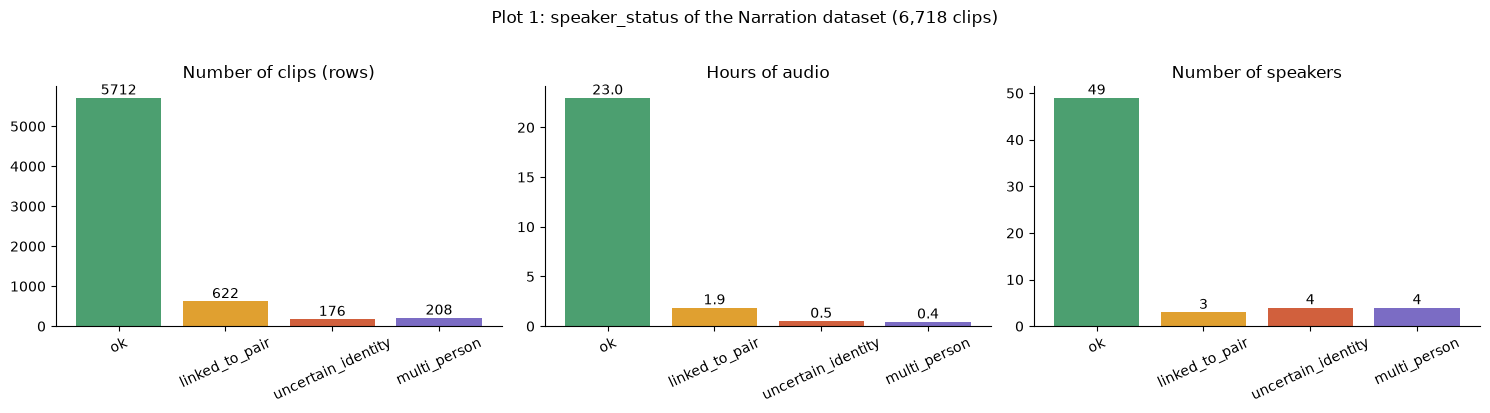

Share of total hours by class (%):
speaker_status
ok                    89.1
linked_to_pair         7.2
uncertain_identity     2.0
multi_person           1.7


In [58]:
print("=" * 100)
print("PLOT 1 - SPEAKER STATUS: how much of the data comes from trustworthy speakers?")
print("=" * 100)
print("""
What each speaker_status means:
  ok                  One identifiable person, consistent gender/age labels, a normal single-speaker recording.
                      -> may be placed in train, validation OR test.
  linked_to_pair      A normal solo speaker, BUT their name also appears in a two-person recording, so they
                      might be the same person as someone in that pair. -> train only (to avoid leaking a voice into test).
  uncertain_identity  The dataset's public speaker ID is inconsistent (several raw IDs, or two different genders / age
                      groups for one ID), so we cannot be sure whose voice it is. -> train only.
  multi_person        A recording where two named people talk ('X and Y'). The voice cannot be assigned to one
                      person. -> train only.
""")
g = M.groupby("speaker_status").agg(clips=("sample_id", "size"), hours=("hours", "sum"), speakers=("speaker_id", "nunique")).reindex(STATUS_ORDER)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["clips", "hours", "speakers"], ["Number of clips (rows)", "Hours of audio", "Number of speakers"]):
    bars = ax.bar(g.index, g[col], color=[STATUS_COLOR[s] for s in g.index])
    ax.bar_label(bars, fmt="%.1f" if col == "hours" else "%d")
    ax.set_title(title); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Plot 1: speaker_status of the Narration dataset (6,718 clips)", y=1.02)
plt.tight_layout(); plt.show()
print("Share of total hours by class (%):")
print((100 * g["hours"] / g["hours"].sum()).round(1).to_string())

PLOT 2 - GENDER OF SPEAKERS (number of speakers and hours, coloured by speaker_status)
'unknown' = no gender recorded (all pair recordings); 'conflicting' = the same speaker has two different gender labels.



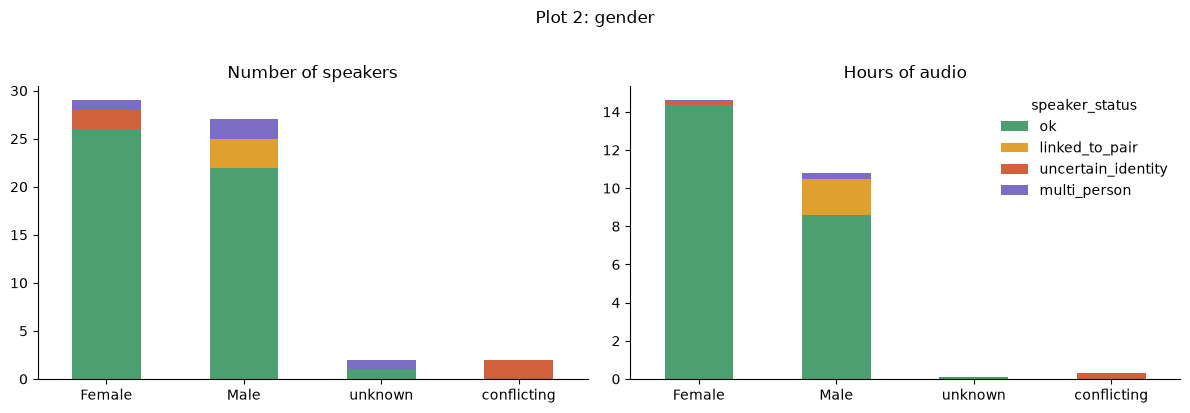

Speakers per gender:
 gender
Female         29
Male           27
unknown         2
conflicting     2 

Hours per gender:
 gender
Female         14.61
Male           10.81
unknown         0.10
conflicting     0.29


In [59]:
print("=" * 100)
print("PLOT 2 - GENDER OF SPEAKERS (number of speakers and hours, coloured by speaker_status)")
print("=" * 100)
print("'unknown' = no gender recorded (all pair recordings); 'conflicting' = the same speaker has two different gender labels.\n")
GENDER_ORDER = ["Female", "Male", "unknown", "conflicting"]
cnt = spk_tbl.pivot_table(index="gender", columns="status", values="hours", aggfunc="count", fill_value=0).reindex(index=GENDER_ORDER, columns=STATUS_ORDER, fill_value=0)
hrs = spk_tbl.pivot_table(index="gender", columns="status", values="hours", aggfunc="sum", fill_value=0).reindex(index=GENDER_ORDER, columns=STATUS_ORDER, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cnt.plot(kind="bar", stacked=True, ax=axes[0], color=[STATUS_COLOR[s] for s in STATUS_ORDER], legend=False)
axes[0].set_title("Number of speakers"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
hrs.plot(kind="bar", stacked=True, ax=axes[1], color=[STATUS_COLOR[s] for s in STATUS_ORDER])
axes[1].set_title("Hours of audio"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="speaker_status", frameon=False)
fig.suptitle("Plot 2: gender", y=1.02); plt.tight_layout(); plt.show()
print("Speakers per gender:\n", cnt.sum(axis=1).to_string(), "\n\nHours per gender:\n", hrs.sum(axis=1).round(2).to_string())

PLOT 3 - AGE GROUP OF SPEAKERS (number of speakers and hours, coloured by speaker_status)


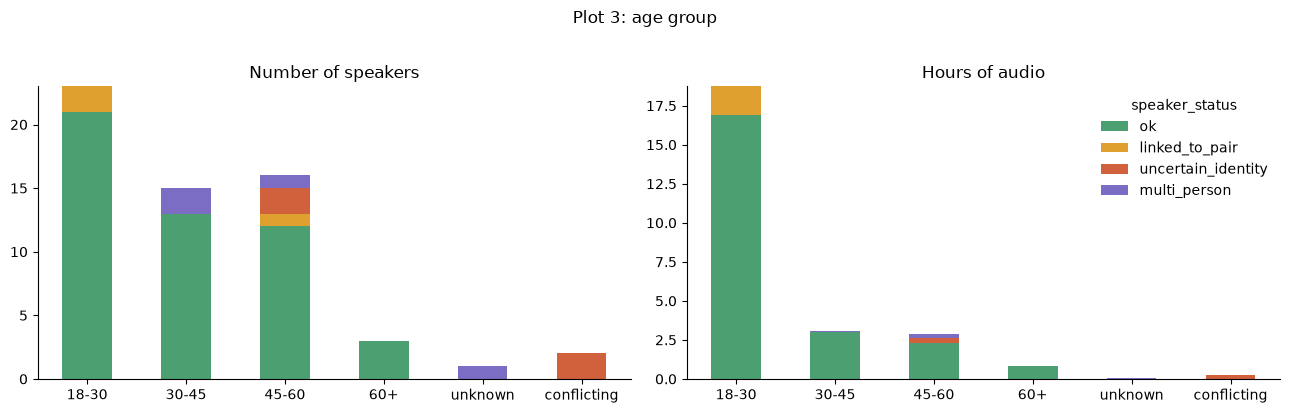

Speakers per age group:
 age
18-30          23
30-45          15
45-60          16
60+             3
unknown         1
conflicting     2 

Hours per age group:
 age
18-30          18.74
30-45           3.07
45-60           2.90
60+             0.81
unknown         0.05
conflicting     0.23


In [60]:
print("=" * 100)
print("PLOT 3 - AGE GROUP OF SPEAKERS (number of speakers and hours, coloured by speaker_status)")
print("=" * 100)
AGE_ORDER = ["18-30", "30-45", "45-60", "60+", "unknown", "conflicting"]
cnt = spk_tbl.pivot_table(index="age", columns="status", values="hours", aggfunc="count", fill_value=0).reindex(index=AGE_ORDER, columns=STATUS_ORDER, fill_value=0)
hrs = spk_tbl.pivot_table(index="age", columns="status", values="hours", aggfunc="sum", fill_value=0).reindex(index=AGE_ORDER, columns=STATUS_ORDER, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt.plot(kind="bar", stacked=True, ax=axes[0], color=[STATUS_COLOR[s] for s in STATUS_ORDER], legend=False)
axes[0].set_title("Number of speakers"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
hrs.plot(kind="bar", stacked=True, ax=axes[1], color=[STATUS_COLOR[s] for s in STATUS_ORDER])
axes[1].set_title("Hours of audio"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="speaker_status", frameon=False)
fig.suptitle("Plot 3: age group", y=1.02); plt.tight_layout(); plt.show()
print("Speakers per age group:\n", cnt.sum(axis=1).to_string(), "\n\nHours per age group:\n", hrs.sum(axis=1).round(2).to_string())

PLOT 4 - GENDER x AGE: hours of audio in each combination (heat map)
Empty or dark cells show groups with very little data - the model will hear few such voices.



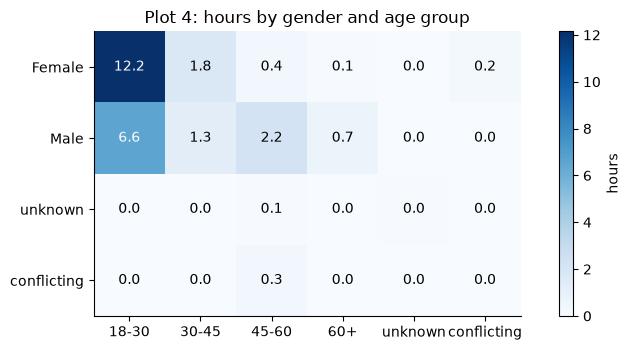

Number of speakers in each combination:


age,18-30,30-45,45-60,60+,unknown,conflicting
gender,,,,,,
Female,13,9,3,2,0,2
Male,10,6,10,1,0,0
unknown,0,0,1,0,1,0
conflicting,0,0,2,0,0,0


In [61]:
print("=" * 100)
print("PLOT 4 - GENDER x AGE: hours of audio in each combination (heat map)")
print("=" * 100)
print("Empty or dark cells show groups with very little data - the model will hear few such voices.\n")
hm = spk_tbl.pivot_table(index="gender", columns="age", values="hours", aggfunc="sum", fill_value=0).reindex(index=GENDER_ORDER, columns=AGE_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(hm.values, cmap="Blues")
ax.set_xticks(range(len(hm.columns)), hm.columns); ax.set_yticks(range(len(hm.index)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.1f}", ha="center", va="center", color="white" if hm.values[i, j] > hm.values.max() * 0.5 else "black")
fig.colorbar(im, label="hours"); ax.set_title("Plot 4: hours by gender and age group"); plt.tight_layout(); plt.show()
sp_hm = spk_tbl.pivot_table(index="gender", columns="age", values="hours", aggfunc="count", fill_value=0).reindex(index=GENDER_ORDER, columns=AGE_ORDER, fill_value=0)
print("Number of speakers in each combination:"); display(sp_hm)

PLOT 5 - HOURS PER SPEAKER: is the dataset dominated by a few voices?


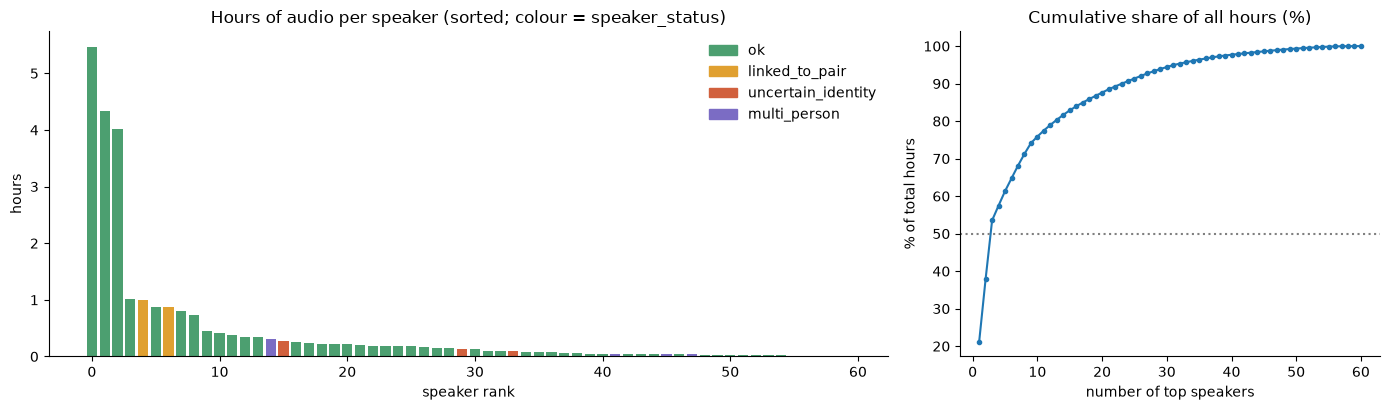

Top 1 speaker  : 21.2% of all hours
Top 3 speakers : 53.5%
Top 5 speakers : 61.3%
Top 10 speakers: 75.9%
Speakers with less than 0.1 h of audio: 28 of 60


In [62]:
print("=" * 100)
print("PLOT 5 - HOURS PER SPEAKER: is the dataset dominated by a few voices?")
print("=" * 100)
s = spk_tbl.sort_values("hours", ascending=False).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(range(len(s)), s["hours"], color=[STATUS_COLOR[x] for x in s["status"]])
axes[0].set_title("Hours of audio per speaker (sorted; colour = speaker_status)"); axes[0].set_xlabel("speaker rank"); axes[0].set_ylabel("hours")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=STATUS_COLOR[k]) for k in STATUS_ORDER], labels=STATUS_ORDER, frameon=False)
cum = 100 * s["hours"].cumsum() / s["hours"].sum()
axes[1].plot(range(1, len(s) + 1), cum, marker="o", ms=3)
axes[1].axhline(50, ls=":", c="grey"); axes[1].set_title("Cumulative share of all hours (%)"); axes[1].set_xlabel("number of top speakers"); axes[1].set_ylabel("% of total hours")
plt.tight_layout(); plt.show()
print(f"Top 1 speaker  : {cum.iloc[0]:.1f}% of all hours")
print(f"Top 3 speakers : {cum.iloc[2]:.1f}%")
print(f"Top 5 speakers : {cum.iloc[4]:.1f}%")
print(f"Top 10 speakers: {cum.iloc[9]:.1f}%")
print(f"Speakers with less than 0.1 h of audio: {(s['hours'] < 0.1).sum()} of {len(s)}")

PLOT 6 - CLIP DURATIONS: how long are the clips, and where is the audio?


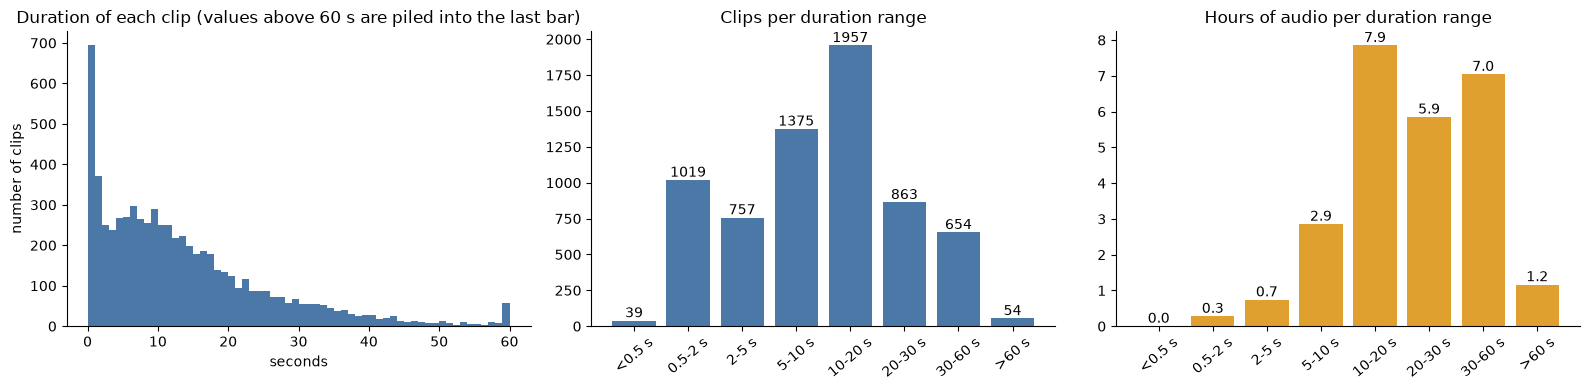

Clips longer than 30 s: 708 clips, 8.21 h (31.8% of all audio) - these cannot be used by models limited to 30 s windows.
Clips shorter than 0.5 s: 39 clips


In [63]:
print("=" * 100)
print("PLOT 6 - CLIP DURATIONS: how long are the clips, and where is the audio?")
print("=" * 100)
bins = [0, 0.5, 2, 5, 10, 20, 30, 60, 200]
labels = ["<0.5 s", "0.5-2 s", "2-5 s", "5-10 s", "10-20 s", "20-30 s", "30-60 s", ">60 s"]
M["dur_bin"] = pd.cut(M["duration_seconds"], bins=bins, labels=labels, right=False)
db = M.groupby("dur_bin", observed=False).agg(clips=("sample_id", "size"), hours=("hours", "sum"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(M["duration_seconds"].clip(upper=60), bins=60, color="#4C78A8")
axes[0].set_title("Duration of each clip (values above 60 s are piled into the last bar)"); axes[0].set_xlabel("seconds"); axes[0].set_ylabel("number of clips")
b = axes[1].bar(db.index.astype(str), db["clips"], color="#4C78A8"); axes[1].bar_label(b); axes[1].set_title("Clips per duration range"); axes[1].tick_params(axis="x", rotation=40)
b = axes[2].bar(db.index.astype(str), db["hours"], color="#E0A030"); axes[2].bar_label(b, fmt="%.1f"); axes[2].set_title("Hours of audio per duration range"); axes[2].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
print(f"Clips longer than 30 s: {(M['duration_seconds'] > 30).sum()} clips, {M.loc[M['duration_seconds'] > 30, 'hours'].sum():.2f} h "
      f"({100 * M.loc[M['duration_seconds'] > 30, 'hours'].sum() / M['hours'].sum():.1f}% of all audio) - these cannot be used by models limited to 30 s windows.")
print(f"Clips shorter than 0.5 s: {(M['duration_seconds'] < 0.5).sum()} clips")

PLOT 7 - MISSING TRANSCRIPTS: how much audio has no text, per original split and per speaker_status?


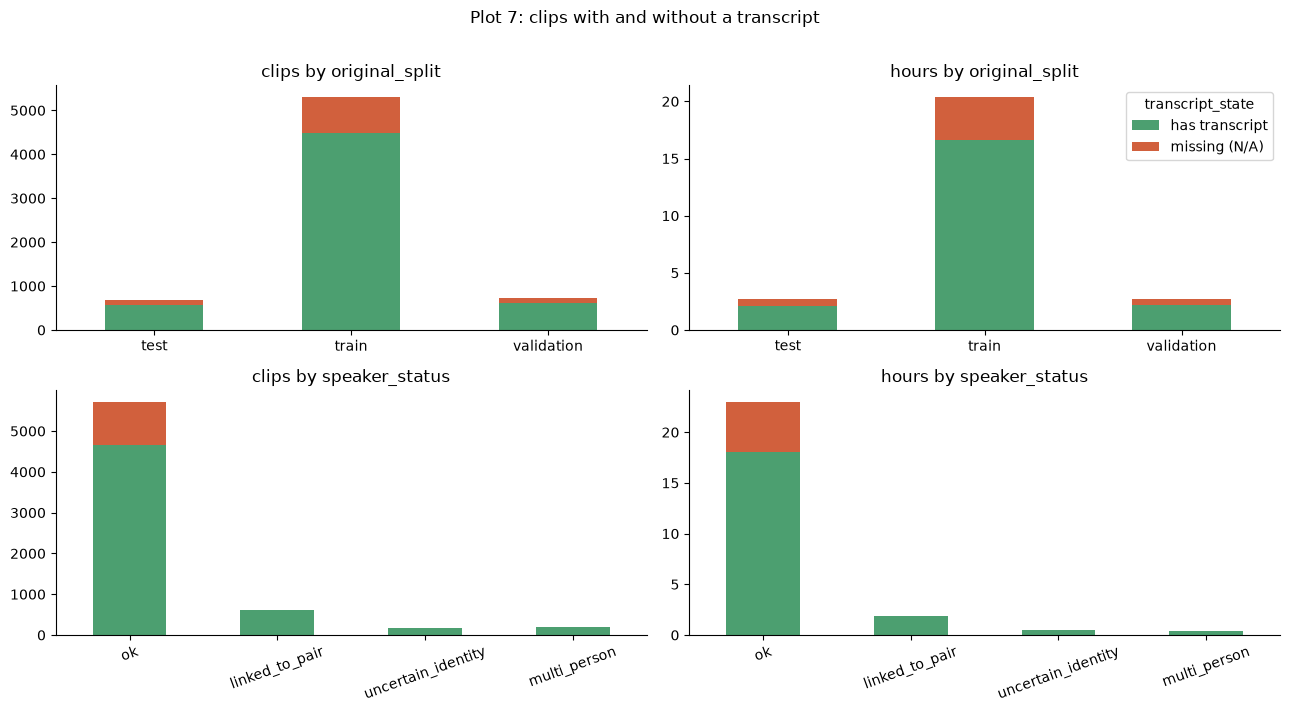

Missing transcripts: 1067 clips = 4.92 h = 19.1% of all audio
They appear in every original split (including test and validation): {'test': 120, 'train': 825, 'validation': 122}


In [64]:
print("=" * 100)
print("PLOT 7 - MISSING TRANSCRIPTS: how much audio has no text, per original split and per speaker_status?")
print("=" * 100)
M["transcript_state"] = np.where(M["transcript_missing"], "missing (N/A)", "has transcript")
by_split = M.groupby(["original_split", "transcript_state"]).agg(clips=("sample_id", "size"), hours=("hours", "sum")).reset_index()
by_stat = M.groupby(["speaker_status", "transcript_state"]).agg(clips=("sample_id", "size"), hours=("hours", "sum")).reset_index()
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for r, (tbl, idx) in enumerate([(by_split, "original_split"), (by_stat, "speaker_status")]):
    for c, val in enumerate(["clips", "hours"]):
        pv = tbl.pivot(index=idx, columns="transcript_state", values=val).fillna(0)
        if idx == "speaker_status": pv = pv.reindex(STATUS_ORDER)
        pv.plot(kind="bar", stacked=True, ax=axes[r, c], color=["#4C9F70", "#D1603D"], legend=(r == 0 and c == 1))
        axes[r, c].set_title(f"{val} by {idx}"); axes[r, c].set_xlabel(""); axes[r, c].tick_params(axis="x", rotation=0 if r == 0 else 20)
plt.suptitle("Plot 7: clips with and without a transcript", y=1.01); plt.tight_layout(); plt.show()
miss = M[M["transcript_missing"]]
print(f"Missing transcripts: {len(miss)} clips = {miss['hours'].sum():.2f} h = {100 * miss['hours'].sum() / M['hours'].sum():.1f}% of all audio")
print("They appear in every original split (including test and validation):", miss.groupby("original_split").size().to_dict())

PLOT 8 - ORIGINAL SPLITS (the authors' train / validation / test): sizes and speaker mix
We will NOT use these splits as they are (speakers appear in several of them), but this shows what the authors made.



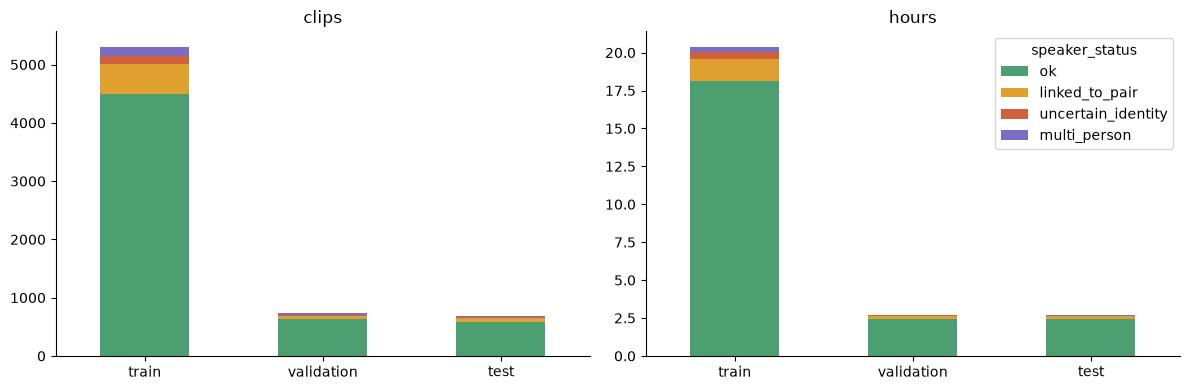

Speakers that appear in more than one of the authors' splits: 57 of 60
Speakers that appear in all three: 49


In [65]:
print("=" * 100)
print("PLOT 8 - ORIGINAL SPLITS (the authors' train / validation / test): sizes and speaker mix")
print("=" * 100)
print("We will NOT use these splits as they are (speakers appear in several of them), but this shows what the authors made.\n")
sp = M.groupby(["original_split", "speaker_status"]).agg(clips=("sample_id", "size"), hours=("hours", "sum")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, val in zip(axes, ["clips", "hours"]):
    pv = sp.pivot(index="original_split", columns="speaker_status", values=val).reindex(columns=STATUS_ORDER).fillna(0).reindex(["train", "validation", "test"])
    pv.plot(kind="bar", stacked=True, ax=ax, color=[STATUS_COLOR[s] for s in STATUS_ORDER], legend=(val == "hours"))
    ax.set_title(val); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
ov = M.groupby("speaker_id")["original_split"].nunique()
print(f"Speakers that appear in more than one of the authors' splits: {(ov > 1).sum()} of {len(ov)}")
print(f"Speakers that appear in all three: {(ov == 3).sum()}")

PLOT 9 - WHAT PEOPLE TALK ABOUT (domain) AND WHERE THEY WERE RECORDED (place)
'(no label)' = the dataset has no domain / place for these clips.



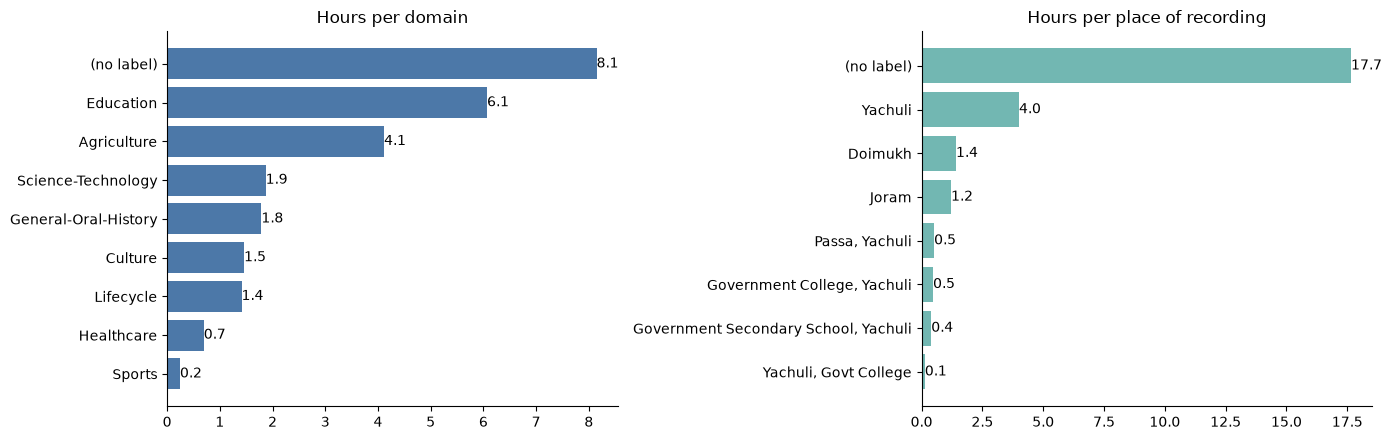

Clips without any domain label: 2879 (8.15 h)
Clips without a place label   : 3839 (17.65 h)


In [66]:
print("=" * 100)
print("PLOT 9 - WHAT PEOPLE TALK ABOUT (domain) AND WHERE THEY WERE RECORDED (place)")
print("=" * 100)
print("'(no label)' = the dataset has no domain / place for these clips.\n")
dom = M.assign(domain=M["domain"].fillna("(no label)")).groupby("domain").agg(clips=("sample_id", "size"), hours=("hours", "sum")).sort_values("hours")
plc = M.assign(place=M["place_of_recording"].fillna("(no label)")).groupby("place").agg(clips=("sample_id", "size"), hours=("hours", "sum")).sort_values("hours")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
b = axes[0].barh(dom.index, dom["hours"], color="#4C78A8"); axes[0].bar_label(b, fmt="%.1f"); axes[0].set_title("Hours per domain")
b = axes[1].barh(plc.index, plc["hours"], color="#72B7B2"); axes[1].bar_label(b, fmt="%.1f"); axes[1].set_title("Hours per place of recording")
plt.tight_layout(); plt.show()
print(f"Clips without any domain label: {M['domain'].isna().sum()} ({M.loc[M['domain'].isna(), 'hours'].sum():.2f} h)")
print(f"Clips without a place label   : {M['place_of_recording'].isna().sum()} ({M.loc[M['place_of_recording'].isna(), 'hours'].sum():.2f} h)")

PLOT 10 - SPEAKING RATE AND TRANSCRIPT LENGTH (finds mismatched transcripts)
Characters per second = number of characters (without spaces) / clip length. Very low = text too short for the audio;
very high = text too long for the audio. Both can mean a wrong transcript or a wrong cut. Only clips >= 0.5 s with a transcript are used.



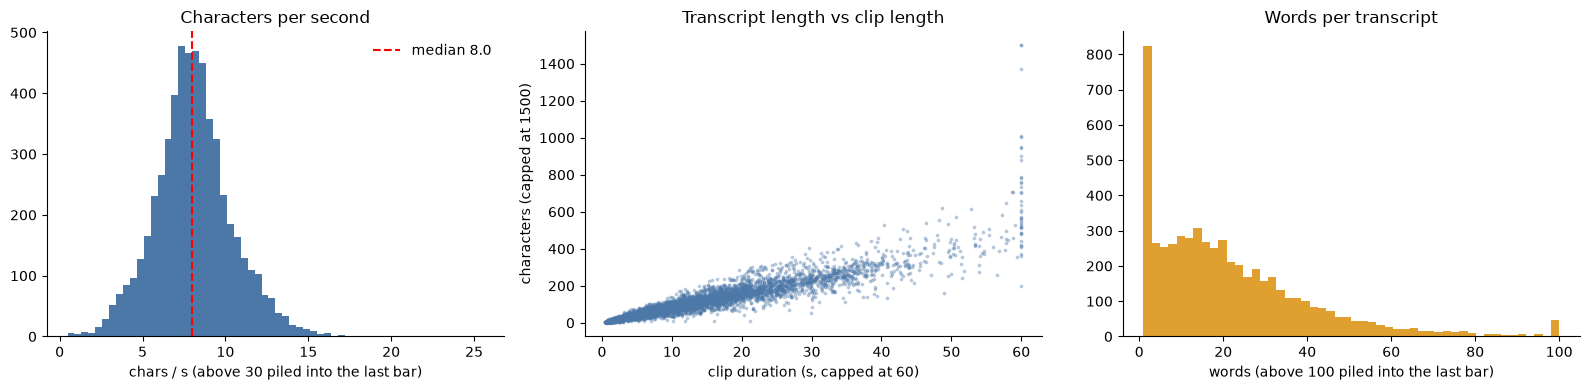

count    5618.00
mean        8.08
std         2.32
min         0.47
25%         6.65
50%         7.98
75%         9.40
max        25.56

Clips with fewer than 3 characters/second: 68   |   more than 20: 1


In [67]:
print("=" * 100)
print("PLOT 10 - SPEAKING RATE AND TRANSCRIPT LENGTH (finds mismatched transcripts)")
print("=" * 100)
print("Characters per second = number of characters (without spaces) / clip length. Very low = text too short for the audio;")
print("very high = text too long for the audio. Both can mean a wrong transcript or a wrong cut. Only clips >= 0.5 s with a transcript are used.\n")
tx = M[~M["transcript_missing"] & (M["duration_seconds"] >= 0.5)].copy()
tx["n_chars"] = tx["transcript_raw"].str.replace(" ", "", regex=False).str.len()
tx["n_words"] = tx["transcript_raw"].str.split().str.len()
tx["cps"] = tx["n_chars"] / tx["duration_seconds"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(tx["cps"].clip(upper=30), bins=60, color="#4C78A8"); axes[0].axvline(tx["cps"].median(), c="red", ls="--", label=f"median {tx['cps'].median():.1f}")
axes[0].set_title("Characters per second"); axes[0].set_xlabel("chars / s (above 30 piled into the last bar)"); axes[0].legend(frameon=False)
axes[1].scatter(tx["duration_seconds"].clip(upper=60), tx["n_chars"].clip(upper=1500), s=3, alpha=0.3, c="#4C78A8")
axes[1].set_title("Transcript length vs clip length"); axes[1].set_xlabel("clip duration (s, capped at 60)"); axes[1].set_ylabel("characters (capped at 1500)")
axes[2].hist(tx["n_words"].clip(upper=100), bins=50, color="#E0A030"); axes[2].set_title("Words per transcript"); axes[2].set_xlabel("words (above 100 piled into the last bar)")
plt.tight_layout(); plt.show()
print(tx["cps"].describe().round(2).to_string())
print(f"\nClips with fewer than 3 characters/second: {(tx['cps'] < 3).sum()}   |   more than 20: {(tx['cps'] > 20).sum()}")

PLOT 11 - WHEN WAS THE DATA RECORDED? (hours per month, from the recording session IDs)
The session ID starts with the recording date. This shows recording campaigns - clips from different campaigns may sound different.



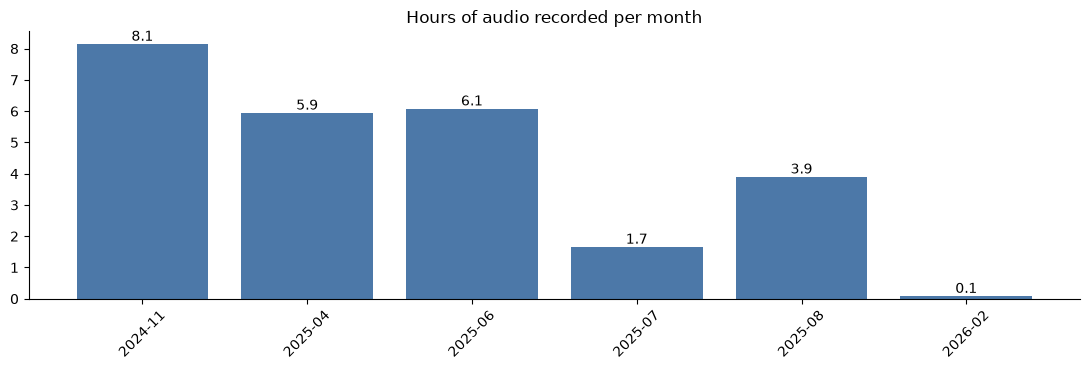

,clips,hours,sessions
rec_month,,,
2024-11,2879,8.15,73
2025-04,1327,5.94,660
2025-06,1526,6.08,912
2025-07,254,1.66,163
2025-08,681,3.90,516
2026-02,51,0.08,9


In [68]:
print("=" * 100)
print("PLOT 11 - WHEN WAS THE DATA RECORDED? (hours per month, from the recording session IDs)")
print("=" * 100)
print("The session ID starts with the recording date. This shows recording campaigns - clips from different campaigns may sound different.\n")
M["rec_month"] = pd.to_datetime(M["recording_session_id"].str[1:9], format="%Y%m%d", errors="coerce").dt.to_period("M").astype(str)
tm = M.groupby("rec_month").agg(clips=("sample_id", "size"), hours=("hours", "sum"), sessions=("recording_session_id", "nunique"))
fig, ax = plt.subplots(figsize=(11, 3.8))
b = ax.bar(tm.index, tm["hours"], color="#4C78A8"); ax.bar_label(b, fmt="%.1f"); ax.set_title("Hours of audio recorded per month"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
display(tm.round(2))

In [72]:
log = pd.read_csv(OUT / "decision_log_A.csv")
log = log.drop(index=len(log) - 1)                     # drop the last (duplicate) line
log.to_csv(OUT / "decision_log_A.csv", index=False, encoding="utf-8-sig")
log[["step", "decision", "rows_affected", "hours_affected"]]

,step,decision,rows_affected,hours_affected
0,3,Narration speaker key = publicSpeakerId (60 speakers),6718,25.799
1,3,speaker_status=uncertain_identity for the 4 conflicting public IDs; train_only,176,0.516
2,3,speaker_status=multi_person for pair recordings ('X and Y'); train_only,208,0.442
3,3,session id = sentenceId prefix without -sliceNNNN (2333 sessions),6718,NaN
4,3,"duration = end_time - start_time (stated, not yet decoded)",6718,NaN
5,3,"speaker_status=linked_to_pair (train_only) for solo speakers whose name appears in a pair recording: jorampaul, jora...",622,1.865
